# bind-the-unknown

**This notebook answers one question about a library design.** Will a model fitted on the first
round of measurements be worth acting on? The answer is a property of how the library was
designed rather than of the target. So it is available before any assay runs. §2.1 shows it
measured, and §2.2 tests it by intervening in both directions.

**Everything above that is the path to a library worth asking the question about.** §1 starts
from a pathogen genome accession and nothing else. It ranks candidate targets, folds the one it
picks, and measures the surface a macrocyclic peptide would have to bind. It then defines a
focused thioether-macrocycle library over that surface. It gets there by calling NCBI, reviewed
UniProt, Europe PMC, EBI HMMER, InterPro, PDBe, 3D-Beacons and AlphaFold DB, ESMFold, RCSB and
ChEMBL. §1.2 makes those calls for real while the notebook is open. Each panel reports what its
call spent, in seconds and outbound requests.

Every number here is computed when the cell runs. It comes out of the records in `runs/`, or out
of a call made while you watch. The code is folded by default; expand any cell to see what
produced a figure.

## 0 · Setup and data availability

**Every record this notebook reads is committed, so it runs in a fresh clone.** The eight
experiment records and `runs/target_ranks.csv` feed §1. The per-batch records and summaries under
`runs/` feed §2. `python -m hpc_pilots summarize` rebuilds those summaries from the records. The
cell below reports which ones this machine can see.

In [1]:
import os, json, glob, re
from pathlib import Path

# The user matplotlibrc on this machine carries `backend : inline`, which is not a valid
# backend outside IPython and prints a red warning on import. Point matplotlib at its own
# config dir so the demo starts clean. Must happen before matplotlib is imported.
os.environ.setdefault("MPLCONFIGDIR", str(Path.cwd() / ".mplcache"))

import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "hpc_pilots").is_dir())
RUNS = ROOT / "runs"
os.chdir(ROOT)          # so `from hpc_pilots import ...` resolves
print(f"repo root: {ROOT}")

# Arm 1: the tracked experiment records, in the order the README tells the story.
ARM1 = ["intake_validation", "holdout_ladder", "identification_cascade", "cross_kingdom_intake",
        "surface_markers", "surface_in_ranker", "amenability_gate", "coverage_channel",
        "onset_chain"]

# Arm 2: written by `python -m hpc_pilots summarize`, and gitignored.
ARM2 = {"method gain table": RUNS / "summary" / "method_policy_gain.csv",
        "target gain table": RUNS / "summary" / "target_metrics.csv"}

rows = [{"arm": "1", "source": f"runs/{n}.json", "present": (RUNS / f"{n}.json").exists()}
        for n in ARM1]
rows += [{"arm": "1", "source": "runs/target_ranks.csv",
          "present": (RUNS / "target_ranks.csv").exists()}]
rows += [{"arm": "2", "source": str(p.relative_to(ROOT)), "present": p.exists()}
         for p in ARM2.values()]

avail = pd.DataFrame(rows)
missing = avail.loc[~avail.present, "source"].tolist()
print(f"{int(avail.present.sum())}/{len(avail)} sources present")
if missing:
    print("\nmissing (rebuild with `python -m hpc_pilots summarize`):")
    for m in missing:
        print("   ", m)
avail

repo root: /Users/ww/Desktop/Desktop - William’s MacBook Pro/YALE/MATS/bind-the-unknown
12/12 sources present


,arm,source,present
0,1,runs/intake_validation.json,True
1,1,runs/holdout_ladder.json,True
2,1,runs/identification_cascade.json,True
3,1,runs/cross_kingdom_intake.json,True
4,1,runs/surface_markers.json,True
5,1,runs/surface_in_ranker.json,True
6,1,runs/amenability_gate.json,True
7,1,runs/coverage_channel.json,True
8,1,runs/onset_chain.json,True
9,1,runs/target_ranks.csv,True


---
## 0.1 · The whole workflow on one page

**Two arms. The first runs from a pathogen genome accession and nothing else; the second
answers one question about a library design.** This is the map for everything below it, and
every count on it is read from one record — `runs/onset_chain.json`, written by running all
five stages of arm 1 on the SARS-CoV-2 reference genome against the live endpoints. Both
references take about 201 seconds end to end.

Read the figure in three passes.

**Down the left column: what gets called, in what order, and what it cost.** Each stage names
the endpoints it reached and the seconds it spent. Stage 1 leads because it is the only tool
runnable from a bare accession that produces facts other tools need — and it produces all four
of them, so the whole chain has a single bottleneck.

**Across to the right column: what each stage actually returned for this genome.** Not what it
could return in principle. These are this run's numbers.

**Then the two orange boxes, which are the arrows that are not there.** A flowchart earns its
place mostly by showing where a chain *fails* to connect. Stage 5 reads nothing that stages 1
to 4 measured, so the library definition is the same library whatever the surface stage found.
And the campaign data that would feed arm 2's answer back into the next design does not exist.
Both are drawn dashed rather than left out.


NC_045512.2   ·   identified through its own curated entries
5 stages, 201 s end to end



,#,what it does,tool,reads,takes,hands on,s
0,1,Genome to candidate proteins,intake.rank_targets,NCBI efetch · UniProt,genome_accession=NC_045512.2,one reviewed accession and one residue range per candidate,11.26
1,2,"Polyproteins to mature chains, and the score for each",intake.decompose + intake.rank_score,UniProt,candidates_in=12,"every chain, with the accession and range its surface is m...",118.13
2,3,"Every chain to a measured surface, or a stated reason",geometry.surface_markers,PDBe · RCSB · UniProt,candidates_in=21,a patch median and range per chain; nothing downstream rea...,71.64
3,4,"A chain to coordinates, the one lane a novel target has",structures.folded,ESM Atlas,candidates_in=21,coordinates. Nothing downstream reads them yet: the surfac...,0.38
4,5,A library definition over the randomised region,chemistry.library_spec,local tables,nothing from upstream,the position count the go/no-go test in arm 2 reads,0.00



how much of each stage's input the next stage covered:



,case,chains_ranked,surface_rows,surface_measured,surface_refused,surface_covers_every_chain,fold_rows,fold_sequence_recovered,fold_covers_every_chain
0,identified through its own curated entries,21,21,20,1,True,21,14,True
1,the pathogen deleted from the reference,20,20,9,11,True,20,4,True


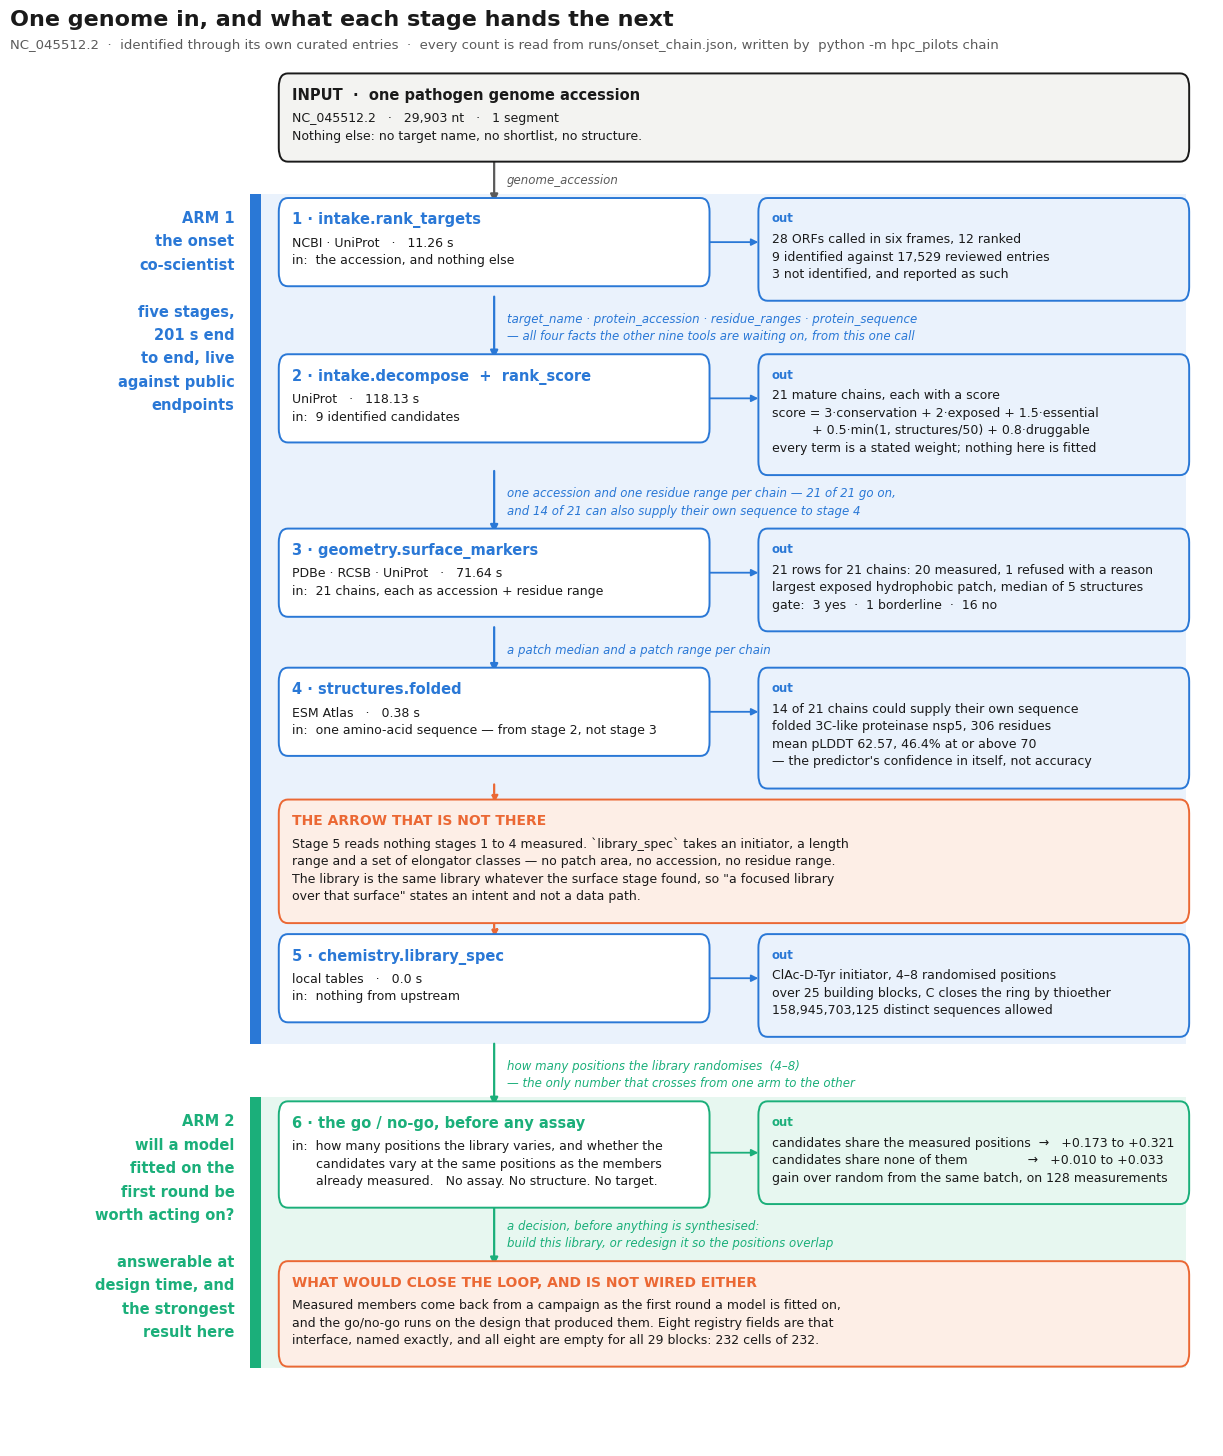

In [2]:
# One knob. The chain was run twice, once against each reference, because which reference the
# genome is identified against changes what every later stage receives. 0 is the genome
# identified through its own curated entries, which is the setting that shows what each stage
# produces; 1 deletes SARS-CoV-2 from the reference first, which is the setting every
# validation run in this notebook uses. The contrast is printed under the figure.
CASE = 0

import sys
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))
import matplotlib.pyplot as plt
import textwrap
import panels

CHAIN = json.loads((RUNS / "onset_chain.json").read_text())
RUN = CHAIN["cases"][CASE]
STAGE = {s["stage"]: s for s in RUN["stages"]}

print(f"{RUN['genome_accession']}   ·   {RUN['case']}")
print(f"{len(RUN['stages'])} stages, {RUN['seconds']:.0f} s end to end\n")

ledger = pd.DataFrame([{
    "#": s["stage"],
    "what it does": s["name"],
    "tool": s["tool"],
    "reads": " \u00b7 ".join(s["endpoints"]),
    "takes": ", ".join(f"{k}={v}" for k, v in s["input"].items()
                       if v not in (None, [], {})) or "nothing from upstream",
    "hands on": s["hands_to_next"],
    "s": s["seconds"]} for s in RUN["stages"]])
pd.set_option("display.max_colwidth", 62)
display(ledger)

# The coverage check, printed rather than claimed, for both cases at once. A stage that emits
# fewer rows than it was handed has dropped something, and this is the line that would say so.
print("\nhow much of each stage's input the next stage covered:\n")
cov = pd.DataFrame([{"case": c["case"], **c["coverage"]} for c in CHAIN["cases"]])
pd.set_option("display.max_colwidth", 46)
display(cov)

# The one pair of numbers in the figure not read from this record: arm 2's two gain ranges,
# quoted from §2.1 and passed in rather than typed inside the figure, so the two cannot drift
# apart without someone editing this line.
fig = panels.workflow_figure(CHAIN, case=CASE, gain_shared="+0.173 to +0.321",
                             gain_unshared="+0.010 to +0.033")
plt.show()

**The ledger above the figure is the same record read as a table**, one row per stage, with
what it takes, what it hands on, and what it spent. Together they answer the question this
notebook used to make a reader assemble from four separate files: put one genome in, and what
does each stage produce?

**The coverage table is the part to check, and it is why the chain is run twice.** Which
reference a genome is identified against changes what every later stage receives, and the two
settings fail in opposite directions.

Identified through its own curated entries, the later stages work: the residue ranges are the
pathogen's own, so the surface stage measures 20 of 21 chains and the folding stage cuts 14 of
21 out of the genome's own translation — including the main protease, which comes out byte for
byte identical to the fold already committed under `runs/folded_structure/`. But conservation is identity to the nearest curated relative, and the nearest relative is the
protein itself, so the term carrying the most weight scores every candidate alike and the top
of the ranking ties. §1.4a shows that.

With SARS-CoV-2 deleted from the reference — the configuration every validation run in §1.4
uses — the ranking separates properly, and the later stages lose most of their input: the
accession and the ranges now belong to a relative, so 9 of 20 chains keep a measurable surface
and only 4 of 20 can supply their own sequence to fold.

**Neither case alone is the system**, and recording one of them and calling it the chain is how
a coverage number comes to be quoted outside the setting that produced it.

**What is true in both: no chain is dropped between stages.** Stage 3 emits one row per chain
stage 2 produced, and a chain with no measurable surface carries the reason on its row. That
was not true before this run. `intake.enrich_with_surface` had no caller anywhere in the
package, so the only surfaces ever measured were six named by hand in a script, and
SARS-CoV-2's RNA-directed RNA polymerase — fifth of the ranked candidates, with an approved
antiviral against it — was not among them. Nothing excluded it; nobody added it. §1.6a shows
every chain.


---
## 1 · Choosing the target and what to measure

### 1.1 · Which tool you can call next

A campaign starts from one fact, a pathogen genome accession. Ask which tool to call and the
tempting answer is whichever sounds most relevant. That answer is not available. From a bare
accession, a literature search has no protein name to search for. A structure lookup has no
accession to look up. Those tools are not irrelevant and not expensive. You just cannot run them
yet. Matching a query against tool summaries never discovers that, because the obstruction is in
what you know and not in the text.

So each tool declares what it needs before it can run, and what its return adds. The selector
then orders all ten:

1. Tools you can run now, before tools you cannot.
2. Among those, whichever produces facts more other tools need.
3. Then whichever answers more of the open questions about the target.
4. Then name, so the order is total and the run reproduces.

Rule 2 beats rule 3 on purpose. Making other tools runnable changes every later round. Answering
one open question changes one number.

**Tools you cannot run yet are reported, never dropped**, each naming the fact it lacks. A tool
one call away is worth knowing about.

In [2]:
from hpc_pilots import selector

start = selector.from_sequence()          # a genome accession, and seven open axes
proposals = selector.rank(start)

print(f"state      : {sorted(start.known)}")
print(f"unresolved : {len(start.unresolved)} axes")
print(f"tools      : {len(proposals)} proposed, "
      f"{sum(p.callable_now for p in proposals)} callable now\n")

board = pd.DataFrame([{
    "tool": p.tool,
    "callable": "yes" if p.callable_now else "—",
    "unlocks": len(p.unlocks),
    "axes": len(p.gates_unresolved),
    "blocked on": ", ".join(p.blocked_on) or "—",
} for p in proposals])

first = selector.first(start)
print(f"first call : {first.tool}  ({first.why})")
print(f"it unlocks : {', '.join(first.unlocks)}")
board

state      : ['genome_accession']
unresolved : 7 axes
tools      : 10 proposed, 5 callable now

first call : intake.rank_targets  (callable now, and unblocks bioactivity.prior_binders, families.entries, geometry.surface_markers, structures.folded, structures.predicted)
it unlocks : bioactivity.prior_binders, families.entries, geometry.surface_markers, structures.folded, structures.predicted


,tool,callable,unlocks,axes,blocked on
0,intake.rank_targets,yes,5,0,—
1,structures.evidence,yes,0,1,—
2,chemistry.library_spec,yes,0,0,—
3,literature.search,yes,0,0,—
4,similarity.homologs,yes,0,0,—
5,geometry.surface_markers,—,0,1,protein_accession
6,bioactivity.prior_binders,—,0,0,protein_accession
7,families.entries,—,0,0,protein_accession|protein_sequence
8,structures.folded,—,0,0,protein_sequence
9,structures.predicted,—,0,0,protein_accession


**Read the table top down.** Five tools can run now and five cannot. Each of the five that
cannot run names the fact it lacks. `intake.rank_targets` leads because it is the only runnable
tool that produces facts another tool needs. It produces all five of them, so identification is
the single bottleneck in the chain. It is also the only tool that enumerates and ranks candidates
rather than answering about one you have already named.

Three of the callable tools produce nothing another tool needs and bear on no open question. The
selector says so rather than quietly ranking them last.

### 1.2 · Watching the tools run

**1.1 decided which tool to call. This section watches all ten run against the real endpoints
while the notebook is open.** Every panel prints the arguments that went out, the status that
came back, and whatever payload arrived. The ten are grouped by the question each answers, and
the order runs from a genome to candidate targets, then to what is already known about a target,
then to what its structure looks like, then to what could bind it.

**Group 1 turns a genome accession into candidates.** `intake.rank_targets` is called on
`NC_045512.2`, the SARS-CoV-2 reference genome, because an accession is the only thing a
campaign holds at onset. It calls ORFs in six frames, identifies them against a reviewed UniProt
reference, and ranks what it finds on conservation, surface exposure, essentiality and
druggability.

**Group 2 asks what is already known about three of those candidates.** `literature.search` goes
to Europe PMC for `nsp12`, to ask whether anyone has published on the target at all.
`similarity.homologs` submits a sequence to EBI HMMER, called that way because what a protein
resembles is answerable from sequence alone when there is no accession to look up.
`families.entries` is called on `P0DTC2`, the spike, for InterPro's residue ranges, since a claim
about a site rather than a protein is what both a structural lookup and a binder need.

**Group 3 puts a structure on the screen.** `structures.evidence` resolves PDBe entries covering
each target's residue ranges, which is how much attention a target has received and not a pocket
score. `structures.predicted` is called on `P0DTD1` to inventory models through 3D-Beacons and
pull per-residue confidence from AlphaFold DB. `structures.folded` folds the main protease
sequence through ESM Atlas, and it is here because it is the only structural lane a genuinely
unknown target can supply: the other two resolve an accession, and a novel protein has none.

**Group 4 asks what could bind it.** `geometry.surface_markers` measures the largest contiguous
exposed hydrophobic patch on deposited coordinates for `P0DTD1`, which is the interface-shaped
quantity a macrocycle needs rather than the enclosed cavity a small-molecule score is calibrated
on. `bioactivity.prior_binders` queries ChEMBL, IEDB and MaveDB for precedent, narrowed to the
molecule class under development. `chemistry.library_spec` returns the library definition off
local tables, so it is the same call with a network or without one.

**`LIVE` is the switch, and `MODE` overrides it one tool at a time.** `True` dispatches for real;
`False` replays committed recordings and touches nothing, which is the setting for a room with no
network. Two panels replay by default: `structures.evidence`, which costs more than a room will
sit through for one lookup, and `intake.rank_targets`, which declares a biopython install this
kernel does not carry. Every panel names the mode it is in, and a live call that comes back empty
or failed falls back to its own recording and says so, which is what an outage looks like here
rather than a traceback. A replayed retrieval panel can show that the call happened and not the
rows that came back, because a trace row keeps the arguments and the status and drops the
payload. The fold is the exception: a live ESMFold call on this sequence returns the committed
file byte for byte, same digest and same mean confidence, and the cell checks that when it runs.

In [3]:
# Edit and re-run. True dispatches the panels below against the real endpoints: five runs in
# close succession on this machine took 32.8, 33.3, 34.7, 47.2 and 50.4 seconds over 33 to 38
# outbound requests, across Europe PMC, EBI HMMER, InterPro, UniProt, 3D-Beacons, AlphaFold
# DB, ESM Atlas, PDBe and RCSB. The EBI HMMER queue sets that spread on its own: it answered
# in 5 to 6 s on three of the five and on the other two sat past the ceiling below, which is
# every second over 35. Budget half a minute and do not be surprised by fifty. The slowest
# tool that returns on every run is InterPro, at about 10 s and 15 requests. False replays
# committed recordings instead and touches nothing, which is the setting for a room with no
# network and takes about a quarter of a second: the fold panel then reads
# runs/folded_structure/ and every other panel reads runs/toolcalls/. A live call that comes
# back empty or failed, which is what an outage looks like here, falls back to its recording
# and says so on screen, with what the failed attempt itself spent.
LIVE = True

# One override per tool, so a presenter can pin any single panel without moving the knob
# above. "live" and "replay" pin that panel; None follows LIVE. The defaults are set from what
# each call measured on this machine, which the plan table at the end of this cell prints
# beside what the registry declares.
MODE = {
    # 11.8 s, and it declares `Bio`, which this kernel does not have
    "intake.rank_targets":       "replay",
    "literature.search":         None,      # 5.2 to 5.5 s and 7 requests
    "similarity.homologs":       None,      # 6.0 to 13.5 s under the 20 s ceiling set below
    "families.entries":          None,      # 10.3 s and 15 requests on the spike
    "structures.evidence":       "replay",  # 59.9 s and 36 requests a call
    "structures.predicted":      None,      # 6.3 s, 2 requests, the one citable return
    "structures.folded":         None,      # 0.7 s warm, 1 request, the only picture here
    # 6.8 s cold and 3.9 s warm over 4 requests, and it is the one measurement in group 4
    "geometry.surface_markers":  None,
    "bioactivity.prior_binders": "live",    # declines itself under the 60 s wall, free
    # local tables, so this is the same call with a network or without one
    "chemistry.library_spec":    "live",
}

# The machinery these panels render through is in notebooks/panels.py: the dispatch
# wrapper, the replay reader and the renderers, which are the same on every run. It is a
# module and not a cell so this page opens on the calls and their output. Cell 2 chdir'd to
# the repo root, so the notebook's own directory goes on the path explicitly.
import sys
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))

import hashlib, textwrap
import numpy as np
import matplotlib.pyplot as plt

import panels
from hpc_pilots.tools import TOOLS, tool
from panels import (call_tool, ca_trace, folded_sequence, group, panel, plddt_on_0_100,
                    rows_table, structure_figure, structure_viewer, _short)

# 600 s is the budget hpc_pilots/exercise.py runs its grids under, and it is wide enough that
# no registered tool declines itself. The refusal panel lowers it on purpose.
WALL_BUDGET_SECONDS = 600
# EBI HMMER queues, and the ceiling is the only part of that a caller controls. Twenty seconds
# is above every measurement this lane has on the record, whose slowest call is 7.3 s, and well
# under the declared default of 120, so a slow queue becomes a bounded failure that falls back
# rather than a long wait. It fired on two of five live runs here, which is the point of it:
# the panel then shows the attempt's own cost above the recording it fell back to.
HMMER_POLL_CEILING = 20.0

FOLDED_JSON = RUNS / "folded_structure" / "mpro_nsp5.json"
FOLDED_PDB = RUNS / "folded_structure" / "mpro_nsp5.pdb"

panels.configure(root=ROOT, runs=RUNS, folded_json=FOLDED_JSON, folded_pdb=FOLDED_PDB,
                 live=LIVE, mode=MODE, wall_budget_seconds=WALL_BUDGET_SECONDS)
panels.plan_table()

LIVE = True  ->  panels dispatch for real, except where MODE pins one to a replay
registry: 10 tools, 9 of them reach the network, 10 with a committed recording
py3Dmol  : present   (the spinnable view; the static figure beside it does not need it)

  tool                       mode             declared                recorded median
  bioactivity.prior_binders  live (pinned)    94.0 s, 16 req          21.914 s, 13 req, 4 calls
  chemistry.library_spec     live (pinned)    0.0 s, 0 req            0.000 s, 0 req, 23 calls
  families.entries           live             21.2 s, 6 req           4.917 s, 7 req, 5 calls
  geometry.surface_markers   live             3.0 s, 4 req            3.655 s, 2 req, 9 calls
  intake.rank_targets        replay (pinned)  0.0 s, ?                11.751 s, 2 req, 2 calls
  literature.search          live             10.0 s, 8 req           5.512 s, 7 req, 7 calls
  similarity.homologs        live             9.0 s, 6 req            2.257 s, 3 req, 5 calls
  

**The ledger at the end lists every registered tool, with the mode it ran in and what the
dispatcher charged it.** It counts the tools off the registry, so a tool cannot drop out of the
account unnoticed.

**The structure is drawn twice from the same returned coordinates.** The py3Dmol cartoon is the
one to spin in the room. It pulls 3Dmol.js from a CDN at render time, and GitHub strips scripts
out of notebook output. So on GitHub that view is blank, and the matplotlib figure beside it is
the only thing a reader there sees. Both are coloured per residue by the same four confidence
bands, from the same normalised vector, so they cannot disagree.

**The file stores pLDDT on a 0 to 1 scale while the bands run 0 to 100.** The cell detects that
rather than assuming it, and then states which convention it normalised to. Reading the B-factor
column as it stands would put all 306 residues in the lowest band. That would look like a
catastrophic prediction instead of a unit error. The threshold the figure draws is read out of
the tool's own `confident_plddt` parameter rather than out of the record. So it is the same
number in a live call on a sequence this machine has never folded.

input sequence   306 residues, recovered from runs/folded_structure/mpro_nsp5.pdb
  sha256         50ec190141bd451b4b7efdf7378d3a516e559004b5335ab9bb341a596691c92e
  record says    50ec190141bd451b4b7efdf7378d3a516e559004b5335ab9bb341a596691c92e
  same sequence  True    target Mpro (nsp5)


─────────────────────────────────────────────────────────────────────────────────────────────
1 · FROM A GENOME TO CANDIDATE TARGETS
intake.rank_targets, over NCBI and reviewed UniProt. The first callable move §1.1 selects,
and the only tool here that enumerates candidates rather than answering about one already
named.
─────────────────────────────────────────────────────────────────────────────────────────────
intake.rank_targets v2    [replay of a committed recording, no network touched]
  arguments      accession='NC_045512.2'
  status         ok    citable False    verified not recorded    source_kind computed
  note           ok: call returned with no note
  measured       11.751 s, 2 outbound 

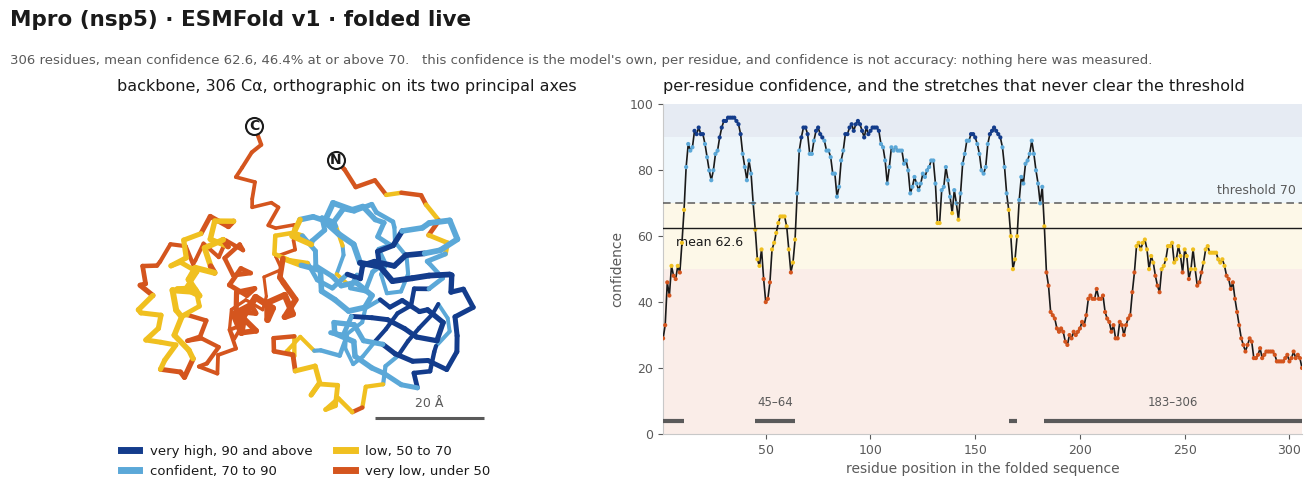

3Dmol.js failed to load for some reason. Please check your browser console for error messages.


  Cold (cache-miss) wall time scales steeply with length -- 1.8 s at 50 residues, 5.0 s at
  200, 12.1 s at 300, 25.6 s at 400 -- and the host caches, so the *second* call on the same
  sequence returns in about 0.7 s. SARS-CoV-2 Mpro (306 aa) took 12.8 s cold and 0.64 s warm.

─────────────────────────────────────────────────────────────────────────────────────────────
4 · WHAT COULD BIND IT
geometry.surface_markers over RCSB and PDBe, bioactivity.prior_binders over ChEMBL, IEDB and
MaveDB, chemistry.library_spec over local tables. One measurement, one refusal, and the
library a campaign would order.
─────────────────────────────────────────────────────────────────────────────────────────────
geometry.surface_markers v1    [LIVE, dispatched for real just now, 4 request(s) out]
  arguments      accession='P0DTD1'
  status         ok    citable True    verified True    source_kind computed
  source         RCSB coordinates via PDBe best_structures, measured with freesasa
  available fr

In [4]:
cite = json.loads(FOLDED_JSON.read_text()) if FOLDED_JSON.exists() else {}
on_disk = FOLDED_PDB.read_text() if FOLDED_PDB.exists() else ""

# The input is recovered from the committed PDB and not retyped, then checked against the
# record's own digest of the sequence it folded. A mismatch here would mean the live call
# below folds something the recording never saw, so it is checked before anything is called.
SEQ = folded_sequence(on_disk) if on_disk else ""
if SEQ:
    print(f"input sequence   {len(SEQ)} residues, recovered from "
          f"{FOLDED_PDB.relative_to(ROOT)}")
    recovered = hashlib.sha256(SEQ.encode()).hexdigest()
    print(f"  sha256         {recovered}")
    print(f"  record says    {cite.get('sequence_sha256', 'no record on this machine')}")
    print(f"  same sequence  {recovered == cite.get('sequence_sha256')}"
          f"    target {cite.get('target_name', '?')}\n")
else:
    print(f"{FOLDED_PDB.relative_to(ROOT)} is not on this machine, so there is no sequence to "
          "fold and the panels below will say so.\n")

# Every panel appends its result here, and the ledger at the end is computed off this list
# rather than off a set written by hand, so a tool cannot drop out of the account unnoticed.
PANELS = []


def shown(result):
    PANELS.append(result)
    return result


group(1, "from a genome to candidate targets",
      "intake.rank_targets, over NCBI and reviewed UniProt. The first callable move §1.1 "
      "selects, and the only tool here that enumerates candidates rather than answering about "
      "one already named.")

# Pinned to replay in MODE, because the tool declares `Bio` and this kernel does not have it.
# A presenter who pins it live gets a panel naming the missing dependency and falling back to
# the same recording, which is why the pin is a default rather than a guard.
intake = shown(call_tool("intake.rank_targets", {"accession": "NC_045512.2"}))
panel(intake)

# The replayed trace row carries the cost and not the ranked list, so the list is read from
# the §1.4 experiment record instead, which is a different call from the one above and is
# labelled as such. `top_percent` is where the target landed among all candidates scored.
ranks = RUNS / "target_ranks.csv"
if ranks.exists():
    tr = pd.read_csv(ranks)
    tr = tr[(tr.pathogen == "SARS-CoV-2") & (tr.holdout_level == "isolate")]
    print("      what this tool put on the board, from runs/target_ranks.csv and not from the "
          "call above")
    print(f"      {'rank':<6}{'top %':<8}{'target':<23}{'countermeasure':<34}status")
    for _, r in tr.iterrows():
        print(f"      {r.pipeline_rank:<6}{r.top_percent:<8}{r.target_protein[:22]:<23}"
              f"{str(r.drug_or_antibody)[:33]:<34}{r.drug_status}")
    print()

group(2, "what is already known about a target",
      "literature.search over Europe PMC, similarity.homologs over EBI HMMER, "
      "families.entries over InterPro. These three return text and tables rather than "
      "coordinates, so each panel prints a few of the rows that actually came back. The "
      "subjects are the targets the panel above ranked fifth, second and first.")

# ---- Europe PMC. Dated literature for one subject, and the axis counts beside it.
lit = shown(call_tool("literature.search", {"subject": "nsp12", "record": False}))
panel(lit, lead=("subject", "subject_kind", "query", "hit_count", "returned",
                 "hits_with_abstract", "preprints_returned"))
rows_table(lit, lambda v: sorted(v["hits"].values(), key=lambda h: int(h["rank"])),
           (("published", 11, lambda h: h["first_publication_date"]),
            ("record", 15, lambda h: f"{h['source']}:{h['id']}"),
            ("journal", 20, lambda h: h["journal"]),
            ("title", 36, lambda h: h["title"])),
           caption="the top hits by relevance, each cited by its own identifier and date")
if lit["envelope"] and lit["envelope"]["value"]:
    axes = lit["envelope"]["value"].get("axes") or {}
    if axes:
        print(textwrap.fill(
            "narrowed hit count per question asked about the target, which is attention "
            "and not evidence: "
            + ", ".join(f"{k} {v['hit_count']}" for k, v in axes.items()), 91,
            initial_indent="      ", subsequent_indent="      "))
        print()

# ---- EBI HMMER. Homologs of the folded sequence, under a bounded poll ceiling.
HOM = ({"query": SEQ, "max_wait_seconds": HMMER_POLL_CEILING, "record": False} if SEQ
       else {"query": "NC_045512.2", "record": False})
hom = shown(call_tool("similarity.homologs", HOM,
                      recorded_as={"query": SEQ} if SEQ else {"query": "NC_045512.2"}))
panel(hom, lead=("homolog_count", "best_identity", "hits_above_inclusion_threshold",
                 "database_name", "database_version", "database_release_date",
                 "database_entries_searched"),
      omit=("identity_warning",))               # printed in full under the rows instead
rows_table(hom, lambda v: v["homologs"],
           (("accession", 11, lambda h: h["accession"]),
            ("entry", 13, lambda h: h["identifier"]),
            ("identity", 9, lambda h: f"{h['identity'] * 100:.1f}%"),
            ("E-value", 10, lambda h: f"{h['evalue']:.1e}"),
            ("organism", 36, lambda h: h["species"])),
           caption="the closest entries HMMER returned, with the identity and E-value it "
                   "measured")
if hom["envelope"] and hom["envelope"]["value"]:
    print(textwrap.fill(hom["envelope"]["value"]["identity_warning"], 91,
                        initial_indent="      ", subsequent_indent="      ") + "\n")

# ---- InterPro. Which curated families claim the spike, and over which residues.
fam = shown(call_tool("families.entries", {"accession": "P0DTC2", "record": False}))
panel(fam, lead=("accession", "protein_name", "organism", "sequence_length",
                 "sequence_source"),
      omit=("interpretation",))
rows_table(fam, lambda v: v["residue_ranges"],
           (("entry", 11, lambda f: f["entry"]),
            ("kind", 23, lambda f: f["type"]),
            ("residues", 16, lambda f: "; ".join(f"{r['start']}-{r['end']}"
                                                 for r in f["ranges"][:2])
                                       + (f" +{len(f['ranges']) - 2}"
                                          if len(f["ranges"]) > 2 else "")),
            ("name", 30, lambda f: f["name"])),
           limit=4,
           caption="assignments with their residue ranges, the form a question about the "
                   "target can use")
if fam["envelope"] and fam["envelope"]["value"]:
    key = fam["envelope"]["value"].get("literature_key") or {}
    if key.get("usable"):
        print(textwrap.fill(
            "this lane also hands the literature lane a query it could not have built from "
            f"an accession alone: {len(key['query_terms'])} family names and "
            f"{len(key['interpro_accessions'])} InterPro accessions, which is the route a "
            "protein with no name of its own takes to Europe PMC.", 91,
            initial_indent="      ", subsequent_indent="      "))
        print()

group(3, "what its structure looks like",
      "structures.evidence over PDBe, structures.predicted over 3D-Beacons and AlphaFold DB, "
      "structures.folded over ESM Atlas. The fold is the only picture in this section and the "
      "only structural lane a genuinely unknown protein can reach.")

# ---- PDBe. Dated deposited coverage per declared target. Pinned to replay in MODE at 59.9 s
# and 36 outbound requests a call, which is the most expensive lookup in the registry.
ev = shown(call_tool("structures.evidence", {}))
panel(ev)

# ---- 3D-Beacons and AlphaFold DB. The one call in the set that returns a citable record.
pred = shown(call_tool("structures.predicted", {"accession": "P0DTD1", "record": False}))
panel(pred, lead=("accession", "sequence_length", "predicted_model_count",
                  "excluded_experimental_count", "earliest_model_created",
                  "latest_model_created", "bytes_received", "alphafold_host_served_models"))
if pred["envelope"] and pred["envelope"]["value"]:
    v = pred["envelope"]["value"]
    print(f"      providers with models      {v.get('providers_with_models')}")
    print(f"      mean confidence by metric  {v.get('mean_confidence_by_metric')}")
    for url in v.get("urls_hit", ()):
        print(f"      hit  {url}")
    print("      the coordinates were not fetched. The payload hands over a model_url per "
          "model and\n      this panel shows what the lookup itself returned, which is the "
          "citable part.\n")

# ---- ESMFold. A pathogen protein sequence in, 3D coordinates out, and the only picture here.
fold = shown(call_tool("structures.folded",
                       {"sequence": SEQ, "target_name": cite.get("target_name", ""),
                        "record": False}))     # an episode passes False; nothing is written
panel(fold, lead=("folded", "residues_modelled", "alignment_verified", "mean_plddt",
                  "median_plddt", "confident_fraction", "pdb_bytes", "pdb_sha256"))

# ---- the equivalence, measured rather than argued
value = fold["envelope"]["value"] if fold["envelope"] else None
if value and cite:
    returned = value["pdb"]
    same = [hashlib.sha256(returned.encode()).hexdigest(), cite["pdb_sha256"],
            hashlib.sha256(on_disk.encode()).hexdigest()]
    print("the same bytes, which is what makes LIVE = False honest for this lane"
          if fold["mode"] == "live" else
          "the recording checked against the file beside it, which catches drift and tests "
          "no endpoint")
    print(f"  sha256 of the pdb this call returned   {same[0]}")
    print(f"  pdb_sha256 the record states           {same[1]}")
    print(f"  sha256 of the committed file on disk   {same[2]}")
    print(f"  bytes {len(returned)} returned against {cite['pdb_bytes']} recorded, "
          f"mean confidence {value['mean_plddt']} against {cite['mean_plddt']} recorded")
    print(f"  all three identical: {len(set(same)) == 1}")
    if fold["mode"] == "replay":
        print("  the call above did not run, so this is only a test of the endpoint when the "
              "bytes\n  came back from it a moment ago, which is what LIVE = True is for.")
    print()

# ---- the structure, rendered twice from the coordinates the call returned
if value:
    resnum, xyz, bfac = ca_trace(value["pdb"])
    plddt, scale_note = plddt_on_0_100(bfac)
    # Out of the registry and not out of the record, so a live fold of a sequence this machine
    # has never seen draws its threshold from the same declaration.
    threshold = next(p for p in tool("structures.folded").parameters
                     if p.name == "confident_plddt")
    print(f"confidence scale {scale_note}, against a tool default of {threshold.default}")
    print(f"  from the file  min {plddt.min():.0f}  max {plddt.max():.0f}  "
          f"mean {plddt.mean():.2f}  at or above {threshold.default:.0f}: "
          f"{(plddt >= threshold.default).mean() * 100:.1f}%\n")
    structure_figure(
        resnum, xyz, plddt,
        f"{cite.get('target_name', 'target')} · {value['model']} · "
        f"{'folded live' if fold['mode'] == 'live' else 'replayed from the committed call'}",
        f"{len(resnum)} residues, mean confidence {plddt.mean():.1f}, "
        f"{(plddt >= threshold.default).mean() * 100:.1f}% at or above "
        f"{threshold.default:.0f}.   this confidence is the model's own, per residue, and "
        "confidence is not accuracy: nothing here was measured.",
        confident_plddt=threshold.default,
        runs=[tuple(r) for r in cite.get("low_confidence_runs", ())])
    plt.show()
    viewer = structure_viewer(value["pdb"], resnum, plddt)
    if viewer is not None:
        viewer.show()

# The fold panel above is fast because the ESM Atlas caches by sequence. Quoting the
# module's own cold measurements rather than restating them means this cannot drift from
# the source, and it keeps the panel from implying that a first fold of a new target is
# as cheap as this one. The quote runs to the end of the Mpro sentence because that is this
# sequence, at this length.
import hpc_pilots.folded_structure as folded_module
cold = re.search(r"Cold \(cache-miss\).*?s warm\.", folded_module.__doc__, re.S)
if cold:
    print("\n" + textwrap.fill(re.sub(r"\s+", " ", cold.group(0)), 93,
                               initial_indent="  ", subsequent_indent="  "))

group(4, "what could bind it",
      "geometry.surface_markers over RCSB and PDBe, bioactivity.prior_binders over ChEMBL, "
      "IEDB and MaveDB, chemistry.library_spec over local tables. One measurement, one "
      "refusal, and the library a campaign would order.")

# ---- RCSB and PDBe. The marker Arm 2 actually needs, and the one quantity in this section
# that is measured on deposited coordinates rather than predicted ones: freesasa runs over the
# `replicates` best structures PDBe returns, which is five by declaration.
geo = shown(call_tool("geometry.surface_markers", {"accession": "P0DTD1"}))
panel(geo, lead=("pdb_id", "chain", "resolution", "residues", "exposed_residues",
                 "exposed_fraction", "total_sasa", "surface_score"))
if geo["envelope"] and geo["envelope"]["value"]:
    v = geo["envelope"]["value"]
    print(f"      largest hydrophobic patch  {v['hydrophobic_patch_area']} Å² over "
          f"{v['hydrophobic_patch_residues']} residues, "
          f"{v['patch_fraction_of_surface'] * 100:.1f}% of the surface, "
          f"{v['patches_found']} patches found")
    print(f"      across {v['structures_measured']} replicate structures  "
          f"{v['patch_area_min']} to {v['patch_area_max']} Å², spread "
          f"{v['patch_area_spread']}")
    print(f"      measured on               {', '.join(v['structures_used'])}\n")

# ---- ChEMBL, IEDB and MaveDB, under a 60 s wall. The tool declines itself, which is the gate
# working: pinned live in MODE because the gate runs here and reaches no network, so this is
# the same panel in a room with no connection.
gate = shown(call_tool("bioactivity.prior_binders", {"accession": "P0DTD1", "record": False},
                       wall_budget_seconds=60, recorded_as={"accession": "P0DTD1"}))
panel(gate)

# ---- Local tables only. The library a campaign would order, and the cheapest call here.
chem = shown(call_tool("chemistry.library_spec", {}))
panel(chem, lead=("initiator", "closure_residue", "theoretical_diversity"),
      omit=("cyclisation", "endpoint_note"))    # printed in full under the alphabet instead
if chem["envelope"] and chem["envelope"]["value"]:
    v = chem["envelope"]["value"]
    print(textwrap.fill(f"random region {v['random_region']} over "
                        f"{len(v['elongator_alphabet'])} elongators: "
                        + ", ".join(v["elongator_alphabet"]), 91,
                        initial_indent="      ", subsequent_indent="      "))
    print(textwrap.fill(f"cyclisation: {v['cyclisation']}", 91,
                        initial_indent="      ", subsequent_indent="      "))
    print(textwrap.fill(v["endpoint_note"], 91,
                        initial_indent="      ", subsequent_indent="      "))
    print()

# ---- the ledger: every registered tool, the mode it ran in, and what it spent
group(None, "what this section just cost",
      "Every registered tool, the mode it ran in, and the wall seconds and outbound requests "
      "the dispatcher measured for it. A replayed row is what the recording measured and not "
      "a cost this run paid, so only the live rows are totalled.")
seen = {}
for r in PANELS:
    seen.setdefault(r["tool"], r)
print(f"  {'tool':<27}{'mode':<10}{'status':<14}{'seconds':>10}{'requests':>10}")
total_seconds = total_requests = 0.0
fell_back = []
for name in sorted(TOOLS):
    r = seen.get(name)
    if r is None:
        print(f"  {name:<27}{'not shown':<10}"
              "no panel above rendered this tool, which is a defect in this cell")
        continue
    env, m = r["envelope"], r["measured"]
    status = (env["status"] if env is not None else
              "refused" if r["refused"] else "absent")
    secs = m["seconds"] if m and m["seconds"] is not None else 0.0
    reqs = m["network_calls"] if m and m["network_calls"] is not None else 0
    # A replay that followed a failed live call still spent what the attempt spent, and that
    # is this run's cost even though the numbers printed on the row are the recording's.
    attempt = r.get("live_attempt")
    if r["mode"] == "live":
        total_seconds += secs
        total_requests += reqs
    elif attempt:
        fell_back.append(name)
        total_seconds += attempt["seconds"]
        total_requests += attempt["network_calls"]
    print(f"  {name:<27}{r['mode']:<10}{status:<14}{secs:>10.3f}{reqs:>10}")
    if attempt:
        print(f"  {'':<27}a live call came first, {attempt['seconds']:.3f} s and "
              f"{attempt['network_calls']} attempted request(s)")
missing = sorted(set(TOOLS) - set(seen))
live_tools = sum(1 for r in seen.values() if r["mode"] == "live")
print(f"\n  {len(seen)} of the {len(TOOLS)} registered tools rendered a panel above"
      + ("." if not missing else f", and these did not: {', '.join(missing)}."))
print(f"  Dispatched live: {live_tools} tool{'' if live_tools == 1 else 's'}, "
      f"{total_seconds:.1f} s and {int(total_requests)} outbound request"
      f"{'' if int(total_requests) == 1 else 's'}. "
      f"Replayed: {len(seen) - live_tools}.")
if fell_back:
    print(textwrap.fill(
        f"{len(fell_back)} of those replays followed a live call that did not come back: "
        + ", ".join(fell_back) + ". What those attempts spent before falling back is counted "
        "in the total above, because a doomed call is still a call.", 93,
        initial_indent="  ", subsequent_indent="  "))

**What is on the screen is a prediction and not a structure.** ESMFold ran single sequence,
with no alignment and no template. pLDDT is the model's own confidence rather than its accuracy.
The mean is 62.6, and 46.4 per cent of residues clear 70. Read as one number, that looks like a
poor result. It is better read as the figure draws it: a confident core, and a long stretch from
183 to 306 that never clears the threshold at all. That stretch is the model saying where it does
not know. Nothing here was checked against an experiment. The record's own `unverified` field
says exactly that about every coordinate and every pLDDT value in it.

**The fold panel is fast because it is a cache hit, and a first fold is not.** The ESM Atlas
caches by sequence. The module's own measurements, quoted above rather than restated, put cold
wall time at 1.8, 5.0, 12.1 and 25.6 seconds for 50, 200, 300 and 400 residues. They name this
very sequence: 306 residues, 12.8 seconds cold against 0.64 warm. Every target this project is
named for is cold on first sight, so the cold number is the one to budget against. The same cache
is why the byte-for-byte equivalence above is a fact about this lane and this sequence, rather
than a general promise. And no replay can promise that the endpoint still answers the same way
today.

**Only one of the ten returns coordinates, and the rest return rows with dates on them.** That is
the shape of the system, and it is what the retrieval panels are there to show. Every figure in
this paragraph and the next is what an endpoint returned on the run this text was written
against. The panels above print whatever comes back today. Europe PMC gave 617 indexed records
for `nsp12`, and the five narrowed search counts beside them. EBI HMMER gave fifty SwissProt
entries measured against the folded sequence, the closest at 100 per cent identity. That is
exactly why the tool carries a standing warning: a homolog is somebody else's accession.
InterPro placed the spike receptor-binding domain at residues 334 to 527 without being told the
domain exists. A residue range is the form a target profile can actually use. It also handed back
24 family names, which is a literature query a bare accession could not have built.
`structures.predicted` returned the lookup rather than the coordinates. It found 95 predicted
models across AlphaFold DB, PED and SWISS-MODEL, the earliest created 2020-10-01, and it reported
both URLs it hit and a `citable` of True. The model files were left unfetched, and the panel says
so on screen.

**The surface marker is the one quantity here measured on deposited coordinates rather than
predicted ones.** `geometry.surface_markers` took the five best structures PDBe lists for P0DTD1
and ran freesasa over each. It returned a largest hydrophobic patch of 762.4 Å², covering 5.3 per
cent of an 8097.7 Å² surface. That patch ranged from 431.4 to 945.7 Å² across the five. The call
cost about four seconds and four requests, it comes back `citable True`, and it names every entry
it measured. Take the spread across replicates as the reading, rather than the single number at
the top. A patch measured once is a patch measured on one crystal. §1.6 charts the same quantity
out of the committed `surface_markers` record.

**The refusal is real and it is the gate working.** `bioactivity.prior_binders` declines itself,
because its declared worst case of 600 seconds does not fit a 60 second budget. Declining costs
nothing and reaches no network. So it is the same panel in a room with no connection, and its
header says so rather than claiming an endpoint was touched. The cost record holds `None` and not
zero for a call that never ran, because a refusal is not a measurement of work.
`structures.evidence` and `intake.rank_targets` are the two panels that show a cost without a
payload. Both replay from `runs/toolcalls/`, where a trace row keeps the arguments, the status
and the cost, and drops the tool's return. The ranked board printed under the second comes from
`runs/target_ranks.csv`, and the panel labels it as a different call. That is the honest way to
put a result on screen that the replayed row does not carry.

### 1.3 · What the recorded experiments found

Eight recorded experiments, each carrying its own question and its own answer. The cell reads the
answer out of each record.

In [4]:
def record(name):
    with open(RUNS / f"{name}.json") as fh:
        return json.load(fh)

found = []
for name in ARM1:
    d = record(name)
    answer = d.get("answer", "")
    found.append({
        "experiment": d.get("experiment", name),
        "status": d.get("status", "?"),
        "corrections": sum(1 for k in d if k.startswith("correction")),
        "finding": (answer[:110] + "…") if len(answer) > 110 else answer,
    })

pd.set_option("display.max_colwidth", 120)
pd.DataFrame(found)

,experiment,status,corrections,finding
0,intake-validation,complete,3,"Yes, across three virus families. Every expected target ranks in the top eight with the pathogen held out, ide…"
1,holdout-ladder,complete,1,"The pipeline needs a relative sharing enough 5-mers, which in practice means one close enough to be conspecifi…"
2,identification-cascade,complete,0,"Yes, by two different mechanisms, and the split between them is the finding. Conserved enzymes are recoverable…"
3,cross-kingdom-intake,complete,0,"Yes, after replacing the candidate-selection step. The identification and ranking transfer unchanged; six-fram…"
4,macrocycle-surface-markers,complete,0,"Yes. Scoring the largest contiguous exposed hydrophobic patch, rather than pocket depth or enclosure, ranks th…"
5,surface-markers-in-the-ranker,complete,0,"No, in both forms tried, and the change is withdrawn. The markers are computed and reported; they are not scor…"
6,amenability-gate-v3,complete,0,"It separates clear refusals from everything else, and the reason it cannot do more is now measured on more tar…"
7,coverage-channel,complete,0,No. It relocates the advantage from the count channel to the dossier-order channel at almost unchanged magnitu…
8,onset-chain-on-one-genome,complete,0,"Five stages run, and the record carries the input and output of each, under both references. The surface stage…"


### 1.4 · Genome to ranked targets

**A genome accession goes in and ranked countermeasure targets come out.** The pathogen's own
proteins are deleted from the reference before indexing. Identification then has to work through
the nearest curated relative. That is the only version of this test that means anything, since
every protein of these pathogens is already curated in UniProt. Four pathogens ran across two
records: the three viruses in `intake_validation`, and the bacterium in `cross_kingdom_intake`.

Each run is scored against a random ranking of the same candidates. `p vs random` is how unlikely
that ranking would be if the pipeline carried no information. `SHOW` picks which pathogen prints
its per-target rows.

In [6]:
# One knob: whose per-target rows print under the summary. Nipah is the default because it is
# the pathogen this section exists to talk about. Any value from the pathogen column works.
SHOW = "Nipah virus"

tr = pd.read_csv(RUNS / "target_ranks.csv")
iv = record("intake_validation")
ck = record("cross_kingdom_intake")

# Virus or bacterium is not a column, so read it off the reference each run indexed against,
# which spells out either "reviewed viral proteins" or "reviewed bacterial proteins".
kind = tr.reference_scope.str.extract(r"reviewed (\w+) proteins")[0]
fams = tr.assign(kind=kind).groupby("kind").pathogen_family.unique()

# Two columns read better out of the records than out of the CSV, so prefer the record where
# it has a value and fall back to the CSV where it does not. best_attainable_p is rounded to
# four places in the CSV, which flattens SARS-CoV-2's 3.0e-05 to 0.0000, and every organism
# name in identified_via is cut to 40 characters there, which ends Nipah's mid-word. The
# bacterium is a separate experiment and cross_kingdom_intake carries no rank-sum block, so
# it keeps the CSV figure for the first of these.
best = {c["pathogen"]: c["rank_enrichment"]["best_attainable_p"] for c in iv["cases"]}
via = {c["pathogen"]: ", ".join(c["nearest_organisms"]) for c in iv["cases"]}
via[ck["pathogen"]] = ck["identified_through"]      # the CSV drops the word "congeneric"

# Every per-pathogen statistic repeats down that pathogen's target rows, so take the first.
one = tr.groupby("pathogen", sort=False).first().reset_index()

# adequately_powered is deliberately not a column here: verdict already carries it one for one
# and the table has to stay readable on a projector. The count underneath is computed from it.
summary = pd.DataFrame({
    "pathogen": one.pathogen,
    "holdout": one.holdout_level,
    "ranked": one.candidate_proteins_ranked,
    "targets": one.targets_scored_for_pathogen,
    "mean pct": one.mean_percentile_of_targets,
    "p vs random": [f"{p:.1e}" for p in one.rank_sum_p_vs_random],
    "best p": [f"{best.get(p, b):.1e}" for p, b in
               zip(one.pathogen, one.best_attainable_p_at_this_size)],
    "verdict": one.verdict,
})

pd.set_option("display.max_colwidth", 40)
print(f"{len(tr)} scored target rows over {len(one)} pathogens")
for k, f in sorted(fams.items(), key=lambda kv: -len(kv[1])):   # viral first, it is 3 of the 4
    print(f"   {k:<10}: {len(f)} {'family' if len(f) == 1 else 'families'}  "
          f"({', '.join(sorted(f))})")
print(f"denominator: {iv['cases'][0]['rank_enrichment']['denominator_rule']}\n")
display(summary)
print(f"\nunderpowered at this size: {int((~one.adequately_powered).sum())} of {len(one)}, "
      "carrying a verdict that says not established rather than a pass or a failure.")

# The bacterium's own record ranks against every gene its gene caller predicted, not against
# the candidates the pipeline identified and ranked, so its worst row disagrees with the CSV.
# Print the gap rather than leaving two numbers for one target in two files and no explanation.
bac = tr[tr.pathogen == ck["pathogen"]]
far = max(ck["first_line_drug_targets"], key=lambda t: t["rank"])
print(f"denominator cross-check: {far['drug']} is rank {far['rank']} of "
      f"{ck['predicted_genes']:,} predicted genes in cross_kingdom_intake, and rank "
      f"{int(bac.pipeline_rank.max())} of {int(bac.candidate_proteins_ranked.iloc[0]):,} "
      "here. One target, two denominators, and the fixed rule above is the one used.")

# ---- one pathogen in full, per target, chosen by SHOW ----
sub = tr[tr.pathogen == SHOW]
if sub.empty:
    print(f"\nSHOW = {SHOW!r} is not in the file. Pick one of: {', '.join(one.pathogen)}")
else:
    r = sub.iloc[0]
    seg = "segment" if r.genome_segments == 1 else "segments"
    art = "an" if r.holdout_level[0] in "aeiou" else "a"
    print(f"\n{r.pathogen}  ·  {r.genome_accession}  ·  {r.genome_nt:,} nt in "
          f"{r.genome_segments} {seg}, called by {r.gene_caller}")
    print(f"reference : {r.reference_scope} minus {r.holdout_removed}, "
          f"{art} {r.holdout_level}-level holdout")
    print(f"found via : {via.get(r.pathogen, r.identified_via)}")
    print(f"verdict   : {r.verdict}\n")
    display(sub[["target_protein", "pipeline_rank", "top_percent",
                 "drug_or_antibody", "drug_status"]].reset_index(drop=True))
    if isinstance(r.caveat, str):
        print("\ncaveat carried in the file for this pathogen:")
        for line in re.findall(r".{1,86}(?:\s|$)", r.caveat):
            if line.strip():
                print("   ", line.strip())

15 scored target rows over 4 pathogens
   viral     : 3 families  (Coronaviridae, Orthomyxoviridae, Paramyxoviridae)
   bacterial : 1 family  (Mycobacteriaceae)
denominator: candidates identified and ranked by the pipeline



,pathogen,holdout,ranked,targets,mean pct,p vs random,best p,verdict
0,SARS-CoV-2,isolate,23,5,18.3,8.6e-04,3.0e-05,beats chance
1,Nipah virus,species,8,3,33.3,7.1e-02,1.8e-02,not established (underpowered)
2,Influenza A PR8,strain,11,3,21.2,1.2e-02,6.1e-03,beats chance
3,Mycobacterium tuberculosis H37Rv,species,1662,4,1.7,4.0e-04,3.0e-04,beats chance



underpowered at this size: 1 of 4, carrying a verdict that says not established rather than a pass or a failure.
denominator cross-check: isoniazid (InhA) is rank 92 of 4,085 predicted genes in cross_kingdom_intake, and rank 63 of 1,662 here. One target, two denominators, and the fixed rule above is the one used.

Nipah virus  ·  NC_002728.1  ·  18,246 nt in 1 segment, called by six-frame ORF
reference : reviewed viral proteins (17,529) minus Nipah virus, a species-level holdout
found via : Hendra virus (isolate Horse/Autralia/Hendra/1994)
verdict   : not established (underpowered)



,target_protein,pipeline_rank,top_percent,drug_or_antibody,drug_status
0,F fusion glycoprotein,1,12.5,none,research target
1,G attachment glycoprotein,3,37.5,m102.4,investigational (compassionate use)
2,L polymerase,4,50.0,remdesivir (in vitro / NHP),investigational



caveat carried in the file for this pathogen:
    UNDERPOWERED: 3 targets among 8 candidates, so even a perfect ranking (1,2,3) reaches
    only p=0.018. Neither a pass nor a failure - the test cannot resolve it. Needs more
    scored targets or more candidates.


**Read `p vs random` against `best p`.** `best p` is the smallest p a pathogen could have
reached if the pipeline had put its targets at the very top. For the three rows that beat chance
the gap is wide, and the observed value sits well inside it. For Nipah the two print at the same
order of magnitude, and the record's verdict is not established at that size.

**M. tuberculosis is the strongest row on rank.** Every first-line drug target sits inside the
top few per cent of its ranked candidates. The table establishes that the ranking recovers the
right targets given a close curated relative. §1.5 pushes that relative away.

### 1.4a · Every candidate's score, and where each number in it came from

**The ranking is one number per protein, and that number is five stated weights times five
features.** Nothing in it is fitted. There is no labelled set of correct target rankings for a
novel pathogen to fit against — that absence is why this project grades decisions rather than
predictions — so a learned weighting would be fitted to whatever its author already believed.
A stated rubric is at least honest about being one.

| weight | feature | what it is |
| ---: | --- | --- |
| 3.0 | conservation | identity to the nearest curated relative that matched this ORF |
| 2.0 | on the outside | whether the chain is annotated where a binder reaches it without crossing a membrane |
| 1.5 | essential | whether the relative's keywords name a function the pathogen cannot lose |
| 0.5 | structures, capped | deposited structures in the family, divided by 50 and capped at 1 |
| 0.8 | druggable class | the best-scoring druggable keyword on the relative |

**The structure count carries the smallest weight on purpose.** It records how much attention a
target has had, which is not how tractable it is, and a ranker leaning on it would be ranking
the literature.

**The surface measurement is deliberately not in this table.** §1.6 measures it, and §1.6's
second panel records the two attempts to score on it — both of which made the ranking worse.


20 chains ranked from NC_045512.2, the pathogen deleted from the reference
rubric: 3.0 x conservation, 2.0 x surface_exposed, 1.5 x essential_class, 0.8 x druggable_class, 0.5 x structures_in_family_capped
the five terms add back to the score on every row, checked when the chain ran: True



,rank,target,3.0 x conservation,2.0 x on the outside,1.5 x essential,"0.5 x structures, capped",0.8 x druggable class,score
0,1,Spike protein S2',1.3860,2.0,1.5,0.42,1.6,6.9060
1,2,3C-like proteinase nsp5,2.5044,0.0,1.5,0.50,2.4,6.9044
2,3,Spike protein S2,1.3860,2.0,1.5,0.40,1.6,6.8860
3,4,Spike protein S1,1.3860,2.0,1.5,0.39,1.6,6.8760
4,5,RNA-directed RNA polymerase nsp12,2.5044,0.0,1.5,0.02,2.4,6.4244
5,6,Papain-like protease nsp3,2.5044,0.0,1.5,0.00,2.4,6.4044
6,7,Helicase nsp13,2.5044,0.0,1.5,0.01,1.6,5.6144
7,8,VME1_BC279 Membrane protein,1.8801,2.0,0.0,0.04,1.6,5.5201
8,9,AP3A_BC279 Protein 3,0.9555,2.0,0.0,0.00,1.6,4.5555
9,10,NCAP_BCRP3 Nucleoprotein,1.9011,0.0,1.5,0.10,0.0,3.5011


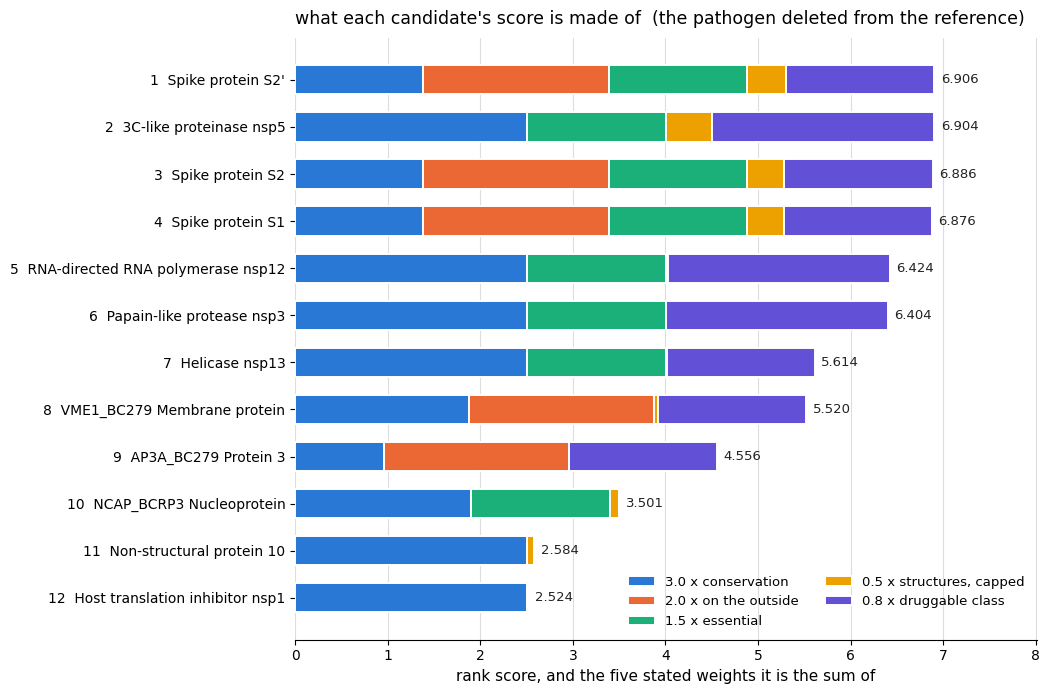


conservation is identity to the nearest curated relative, so which reference is used decides
what the heaviest term in the rubric can tell apart:

   identified through its own curated entries
      conservation takes 2 distinct value(s) over 21 chains: [0.9992, 1.0]
      14 distinct scores, largest tie 4 chains, top of the list tied: True
   the pathogen deleted from the reference
      conservation takes 7 distinct value(s) over 20 chains: [0.3011, 0.3185, 0.462, 0.5385] ...
      16 distinct scores, largest tie 4 chains, top of the list tied: False


In [5]:
# Two knobs. SHOW_CHAINS is how many ranked chains the table and the chart print, and
# SCORE_CASE is which reference they are scored against. 1 is the holdout, which is the
# configuration every validation run here uses and the only one in which the ranking
# separates anything.
SHOW_CHAINS = 12
SCORE_CASE = 1

# Checked rather than chosen: the worst adjacent pair separates at OKLab dE 9.1 under
# protanopia and 22.9 under normal vision, and every segment is named in the legend and in
# the table above it, so nothing rests on the colour being seen.
TERMS = [("conservation", "3.0 x conservation", "#2a78d6"),
         ("surface_exposed", "2.0 x on the outside", "#eb6834"),
         ("essential_class", "1.5 x essential", "#1baf7a"),
         ("structures_in_family", "0.5 x structures, capped", "#eda100"),
         ("druggable_class", "0.8 x druggable class", "#6250d6")]

scase = CHAIN["cases"][SCORE_CASE]
sstage = {s["stage"]: s for s in scase["stages"]}
scored = scase["scores"]
tbl = pd.DataFrame([{"rank": s["rank"], "target": s["target"],
                     **{label: s["score_terms"][key] for key, label, _ in TERMS},
                     "score": s["score"]} for s in scored])

print(f"{len(scored)} chains ranked from {scase['genome_accession']}, {scase['case']}")
print("rubric: " + ", ".join(f"{v} x {k}" for k, v in
                             sstage[2]["output"]["rubric"].items()))
print("the five terms add back to the score on every row, checked when the chain ran: "
      f"{sstage[2]['output']['all_decompositions_reproduce_the_score']}\n")
pd.set_option("display.max_colwidth", 40)
display(tbl.head(SHOW_CHAINS))

# Stacked, because the question is not which protein scores highest but what each one's score
# is made of. Two candidates a thousandth apart can be there for opposite reasons, and one
# bar per protein is exactly the picture that hides it.
rows = scored[:SHOW_CHAINS][::-1]
fig, ax = plt.subplots(figsize=(10.6, 0.42 * len(rows) + 2.0))
left = [0.0] * len(rows)
for key, label, colour in TERMS:
    widths = [r["score_terms"][key] for r in rows]
    ax.barh(range(len(rows)), widths, left=left, height=0.62, color=colour,
            edgecolor="white", linewidth=1.4, label=label, zorder=3)
    left = [a + b for a, b in zip(left, widths)]
for y, total in enumerate(left):
    ax.text(total + 0.07, y, f"{total:.3f}", va="center", ha="left", fontsize=9.5,
            color="#222222", zorder=4)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{r['rank']}  {r['target'][:40]}" for r in rows], fontsize=10)
ax.set_xlabel("rank score, and the five stated weights it is the sum of", fontsize=11)
ax.set_title(f"what each candidate's score is made of  ({scase['case']})",
             fontsize=12.5, loc="left", pad=10)
ax.set_xlim(0, max(left) * 1.16)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.xaxis.grid(True, color="#DDDDDD", lw=0.8)
ax.set_axisbelow(True)
ax.legend(loc="lower right", frameon=False, fontsize=9.5, ncols=2)
fig.tight_layout()
plt.show()

# What the reference does to the ranking, measured rather than argued: the same genome, the
# same rubric, the holdout flipped.
print("\nconservation is identity to the nearest curated relative, so which reference is "
      "used decides\nwhat the heaviest term in the rubric can tell apart:\n")
for c in CHAIN["cases"]:
    values = sorted({s["conservation"] for s in c["scores"]})
    ties = {}
    for s in c["scores"]:
        ties.setdefault(s["score"], []).append(s["target"])
    top = max(ties)
    print(f"   {c['case']}")
    print(f"      conservation takes {len(values)} distinct value(s) over "
          f"{len(c['scores'])} chains: {values[:4]}{' ...' if len(values) > 4 else ''}")
    print(f"      {len(ties)} distinct scores, largest tie {max(len(v) for v in ties.values())}"
          f" chains, top of the list tied: {len(ties[top]) > 1}")

**The stacked bar is the point of this section.** Two candidates a thousandth of a point apart
can arrive there by opposite routes, and one bar per protein hides exactly that. Read across a
row and you can see which of the five terms a candidate earned and which it did not: the spike
chains earn 2.0 for sitting on the outside of the virion and lose on conservation, the replicase
chains do the reverse.

**The contrast printed under the chart is what the holdout is for.** Against a reference that
still holds the pathogen's own entries, conservation takes 2 distinct values across 21 chains,
the ranking collapses to 14 distinct scores, and the top of the list is a tie. Delete the
organism first and the same rubric on the same genome separates 20 chains into 16 scores. That
is not a defect in the rubric — it is the reason every validation run in §1.4 deletes the organism
before it ranks anything.


### 1.5 · The identification cliff

**Push the nearest curated relative further away and the pipeline does not degrade, it stops.**
The test runs the whole path again and again. Each time it deletes one more layer of the
pathogen's relatives from the reference. One step below success every expected target is gone,
and identification is down to zero or one open reading frame.

**Failure comes back empty rather than wrong.** At the SARS-CoV-2 species step the pipeline
latched onto a *Rat coronavirus* and still returned 0 of 5 expected targets. With no relative it
recognises, it returns nothing rather than a confidently wrong list.

**Which step the cliff falls on differs between the two pathogens.** The reason matters more than
the step. Nipah survives losing its own species, because Hendra is a separate species in the same
genus. SARS-CoV-2 does not, because SARS-CoV is the same species. Removing it removes every close
relative at once. The real limit is how much exact short-stretch sequence identity the two share,
and taxonomic rank is only a proxy for that.

**Past the cliff, two mechanisms recover two different kinds of protein.** The fallback runs
identification again with a whole clade gone. It tries distant relatives first. Then it reads the
shape of the sequence itself, on whatever the exact-match search could not place. `CASCADE`
switches the lower panel between the family step and the order step.

In [7]:
# Edit and re-run: which holdout depth the cascade panel reports.
# "coronaviridae_removed" is the family rung, "nidovirales_removed" the order rung.
CASCADE = "coronaviridae_removed"

from textwrap import fill

lad, casc = record("holdout_ladder"), record("identification_cascade")

wrap = lambda s: fill(s, 95, initial_indent="  ", subsequent_indent="  ")

# Record text is quoted rather than paraphrased, and pulled by keyword rather than by index, so
# a reordered record still prints the line this section is about and a deleted one prints
# nothing instead of raising. The answer field is split into sentences because the sentence that
# gives the reason for the cliff is one of three in a paragraph.
def says(d, word):
    pool = re.split(r"(?<=\.)\s+", d.get("answer", "")) + d.get("findings", [])
    return next((s for s in pool if word in s.lower()), "")

def quote(d, *words):
    for w in words:
        if says(d, w):
            print(wrap(says(d, w)))

rows = []
for pathogen, L in lad["ladders"].items():
    for r in L["rungs"]:
        rows.append({
            "pathogen": pathogen,
            "step": r["rank"].split(" (")[0],
            # The isolate rung matches entries by name rather than removing a clade, so the
            # record stores a sentence there instead of a count. Left blank, not called 0.
            "removed": r["removed"] if isinstance(r["removed"], int) else None,
            "orfs": r["orfs_identified"],
            "_found": r["expected_targets_found"],
            "targets": f'{r["expected_targets_found"]} / {r["of"]}',
            # Organism strings carry an isolate parenthetical and the record truncates some of
            # them mid-word, so only the organism name is kept here.
            "found via": ", ".join(o.split(" (")[0]
                                   for o in r.get("identified_through") or []) or "—",
        })
ladder = pd.DataFrame(rows)

# The cliff is the shallowest rung at which no expected target comes back. Only that rung is
# marked: everything below it is already over the edge, and marking it all hides the shape.
cliff = {p: g.index[0] for p, g in
         ladder[ladder["_found"] == 0].groupby("pathogen", sort=False)}
ladder["cliff"] = ["<-- cliff" if i in cliff.values() else "" for i in ladder.index]
ladder["removed"] = ladder.removed.map(lambda v: "—" if pd.isna(v) else f"{int(v):,}")

# Rung ordering is taxonomic and the record does not state it, so it is read off the longest
# ladder rather than typed here. Not every pathogen has every rung: Nipah's ladder has no
# isolate rung and stops at family, and the table shows that gap rather than filling it.
deepest = max(lad["ladders"].values(), key=lambda L: len(L["rungs"]))
print("holdout ladder: push the nearest curated relative one taxonomic rank further away")
print("holdout steps, shallowest first: "
      + " < ".join(r["rank"].split(" (")[0] for r in deepest["rungs"]))
print("removed counts the reference entries dropped at that step, and orfs counts the")
print("candidate proteins identification brought back\n")
display(ladder.drop(columns="_found"))

print()
pad = max(len(p) for p in ladder.pathogen)
for p, i in cliff.items():
    # Guarded because a record in which a pathogen failed on its own shallowest rung has no
    # rung above the cliff to report, and that is a thing this ladder could legitimately find.
    held = ladder.loc[i - 1] if i and ladder.loc[i - 1, "pathogen"] == p else None
    n = ladder.loc[i, "orfs"]
    fall = (f'falls at {ladder.loc[i, "step"]} to {ladder.loc[i, "targets"]} '
            f'on {n} candidate protein{"" if n == 1 else "s"}')
    print(f'  {p:<{pad}}  ' + (f'holds at {held.step} with {held.targets}, then {fall}'
                               if held is not None else f'{fall}, the shallowest step tested'))

print("\n  what the ladder record concludes, in its own words:")
quote(lad, "cliff", "proxy", "calibrated")

# Past the cliff: what the three tiers get back, and as what. The unplaced ORFs are counted
# alongside the placed ones because how many were placed, and which, is the result itself.
c = casc[CASCADE]
orfs = pd.DataFrame(c["rows"])
placed = orfs[orfs.tier.notna()].copy()
panel = placed.assign(
    residues=placed["len"],
    # Truncated so that a future record carrying a long description cannot blow the table
    # width; the longest name in either rung today is well inside this.
    **{"placed as": placed["name"].str.slice(0, 40),
       "through": placed["org"].map(lambda o: o.split(" (")[0] or "—"),
       "E value": placed["ev"].map(lambda e: "—" if pd.isna(e) else f"{e:.1e}")}
).rename(columns={"tier": "found by"})[
    ["residues", "found by", "placed as", "through", "E value"]]

print(f'\n\nthe three ways identification tries to place a protein, '
      f'{CASCADE.replace("_", " ")}:')
print(f'{c["rank"]} rank, {c["removed"]:,} reference entries removed, {c["secs"]} s')
print(f'{len(orfs)} candidate proteins in, {len(placed)} placed, '
      f'{len(orfs) - len(placed)} unplaced '
      f'(lengths {", ".join(str(v) for v in orfs["len"][orfs.tier.isna()])})\n')
tpad = max(len(t["tier"]) for t in casc["tiers"])
for t in casc["tiers"]:
    print(f'  {t["tier"]:<{tpad}}  {t["reaches"]}')
print()
display(panel.reset_index(drop=True))

print("\n  what that record concludes, over both steps and not just the one above." + chr(10) + "  Its own words for a step and for a way of identifying are rung and tier:")
quote(casc, "tobaniviridae", "spike")

holdout ladder: push the nearest curated relative one taxonomic rank further away
holdout steps, shallowest first: isolate < species < genus < family < order
removed counts the reference entries dropped at that step, and orfs counts the
candidate proteins identification brought back



,pathogen,step,removed,orfs,targets,found via,cliff
0,SARS-CoV-2,isolate,—,8,5 / 5,"Bat coronavirus HKU3, SARS-CoV",
1,SARS-CoV-2,species,69,1,0 / 5,Rat coronavirus,<-- cliff
2,SARS-CoV-2,genus,320,1,0 / 5,—,
3,SARS-CoV-2,family,486,0,0 / 5,—,
4,SARS-CoV-2,order,548,0,0 / 5,—,
5,Nipah virus,species,9,8,3 / 3,Hendra virus,
6,Nipah virus,genus,18,0,0 / 3,—,<-- cliff
7,Nipah virus,family,342,0,0 / 3,—,



  SARS-CoV-2   holds at isolate with 5 / 5, then falls at species to 0 / 5 on 1 candidate protein
  Nipah virus  holds at species with 3 / 3, then falls at genus to 0 / 3 on 0 candidate proteins

  what the ladder record concludes, in its own words:
  Failure is a cliff and not a slope. One rung below success, identification falls to zero or
  one ORF rather than returning a degraded ranking.
  Nipah survives a species holdout and SARS-CoV-2 does not. Hendra and Nipah are separate
  species in one genus; SARS-CoV and SARS-CoV-2 are one species. The pipeline's limit is
  sequence identity and taxonomic rank is only a proxy for it.
  The taxonomic rank at which this happens differs between families, because viral species
  boundaries are not calibrated to sequence identity.


the three ways identification tries to place a protein, coronaviridae removed:
family rank, 486 reference entries removed, 29 s
8 candidate proteins in, 3 placed, 5 unplaced (lengths 419, 275, 222, 121, 121)

  exa

,residues,found by,placed as,through,E value
0,2595,remote,R1AB_WBV24 Replicase polyprotein 1ab,White bream virus,8.9e-68
1,4405,remote,R1AB_BEV Replicase polyprotein 1ab,Berne virus,6.5e-10
2,1282,topology,unidentified probable surface antigen,—,—



  what that record concludes, over both steps and not just the one above.
  Its own words for a step and for a way of identifying are rung and tier:
  With all of Coronaviridae removed, both replicase halves are found through Tobaniviridae --
  White bream virus at E=8.9e-68 and Berne virus at E=6.5e-10. Nidovirus replicases are
  genuinely homologous across families and exact 5-mers simply could not see them.
  The spike is found by neither tier of homology at any holdout level, and that is correct
  rather than a failure: it has no homolog outside Coronaviridae. The topology tier recovers it
  as a probable surface antigen from a signal peptide, three transmembrane segments and twenty-
  two glycosylation sequons.


**The proteins this project cares about are the ones with no distant relatives anywhere.**
Conserved enzymes come back across families, because they genuinely are homologous. With all of
Coronaviridae removed, both replicase halves are recovered through Tobaniviridae. The spike is
recovered by neither homology search at any holdout level. The record says that is correct rather
than a failure, because there is no relative to find outside Coronaviridae. It is recognised from
its own sequence instead, as a surface protein rather than by name. The signs are the signal
peptide, the membrane-spanning segments and the sugar-attachment sites it carries.
Family-specific surface proteins are exactly the antibody targets, and a macrocycle binding a
viral surface is the same problem. So the step that matters most here is the one that depends
least on there being a relative at all.

**Shape alone names a class and not a protein.** This step can say it has found a surface protein
and cannot say which one. That is why it runs only where homology found nothing.

### 1.6 · The surface a macrocycle would bind

**A macrocycle needs a flat greasy area, not a pocket, so that is what gets measured here.** The
quantity scored is the largest unbroken exposed hydrophobic patch. It is not pocket depth and not
enclosure, because a macrocycle lies flat across several hundred square angstroms rather than
reaching into a cavity. Scoring depth would reproduce an enzyme bias through geometry, so the
choice of what to measure is the experiment. This choice puts the spike receptor-binding domain
above the main protease, the reverse of a small-molecule druggability score. The cell checks that
ordering at every contact cutoff measured, rather than at the one that flatters it.

**The measurement moves with whichever structure you pick.** Measuring the same domain over five
structures moves the patch by up to 496.2 square angstroms. That is why the chart draws the
measured range as the bar, and the median as a tick inside it. The gate asks first whether the
surface is on the outside of the cell at all. It then asks whether the area clears one macrocycle
footprint, 600 square angstroms, across every structure measured.

marker, 6 structures, one per target, scored at 3 contact cutoffs
  at 10 angstroms: enzyme mean score 2.82, non-enzyme 3.67, gap +0.84
  the comparison a macrocycle cares about, patch in square angstroms, at each:
       8 angstroms   Spike RBD    682   Mpro    320   enzyme gap +0.43
      10 angstroms   Spike RBD    682   Mpro    415   enzyme gap +0.84   <- CONTACT_CUTOFF
      12 angstroms   Spike RBD   1186   Mpro    551   enzyme gap +0.34

12 targets declared in hpc_pilots/configs/structures.json, 12 rows, nothing dropped: True
gate, 11 targets, median patch area over 5 structures each, square angstroms
verdicts recomputed from hpc_pilots.intake.amenable: all 11 agree with the record
rule: localisation first, then yes needs the whole range at or above 600,
      no needs it all below 300, and a range between the two is borderline whatever the median says
refused on localisation: PLpro (nsp3), RdRp (nsp12), nsp10/nsp16 interface, Mpro (nsp5), PA-PB1 interface, nsp13 helicase
  of t

,target,modality,exposed,patch_median,low,high,spread,gate
0,HA stem (HA2 helix A),none approved,True,301.8,256.5,1130.8,874.3,borderline
1,F fusion glycoprotein,none approved,True,362.6,357.2,381.5,24.3,borderline
2,PLpro (nsp3),none approved,False,404.9,358.5,409.6,51.1,no
3,G attachment glycoprotein,antibody,True,447.4,364.2,512.1,147.9,borderline
4,RdRp (nsp12),small molecule,False,486.6,362.9,1682.7,1319.8,no
5,nsp10/nsp16 interface,none approved,False,563.1,279.7,958.8,679.1,no
6,Mpro (nsp5),small molecule,False,651.0,625.1,824.6,199.5,no
7,PA-PB1 interface,none approved,False,686.9,683.8,870.7,186.9,no
8,Spike RBD,antibody,True,842.3,592.0,1088.2,496.2,borderline
9,nsp13 helicase,none approved,False,1247.2,998.4,1303.3,304.9,no



no surface measured for NA catalytic site:
   PDBe maps no deposited chain to P03470 at all, so the range cannot be covered by
   anything. The protein may be well solved under another accession; this entry is not it.


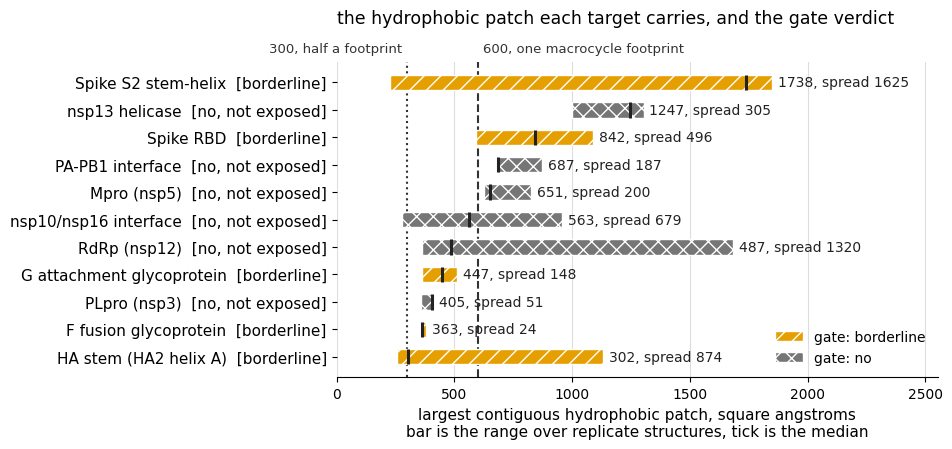


withdrawn, runs/surface_in_ranker.json
  No, in both forms tried, and the change is withdrawn. The markers are computed and reported; they are not scored.

p against random for the recovered targets of each pathogen, lower is better:

  SARS-CoV-2   none 0.0014   added 0.0009 (0.7x better)   centred 0.0201 (14.1x worse)
  Nipah virus  none 0.0714   added 0.3929 (5.5x worse)   centred 0.1250 (1.8x worse)

why added fails:
  The term cannot be earned by a candidate with no deposited structure, so every such
  candidate falls below every candidate that has one. That is a penalty for being
  understudied, aimed at exactly the novel targets the system exists to find. SARS-CoV-2's
  spike went from first to fifth on surface_score None; Nipah's p went 0.071 to 0.393.

why centred fails:
  The mirror failure. Centred on the mean of six reference structures, most real candidates
  score below it, so having a structure became the penalty and the top five were again
  everything with no structur

In [6]:
# Knob: which contact cutoff of the marker sweep to summarise. The record carries 8.0, 10.0
# and 12.0, all three are printed below whichever is picked, and 10.0 is the conventional
# interface definition. An unknown value prints the available ones instead of guessing.
CONTACT_CUTOFF = 10.0

from hpc_pilots import intake
from hpc_pilots.intake import MACROCYCLE_FOOTPRINT_A2 as FOOTPRINT
import matplotlib.pyplot as plt
import textwrap

mark_rec = record("surface_markers")
gate_rec = record("amenability_gate")
wd_rec = record("surface_in_ranker")

# The marker, and the one comparison the section rests on checked at every cutoff that was
# measured, so "the direction does not depend on the cutoff" is verified when the cell runs
# rather than asserted in prose.
sweep = {b["contact_angstrom"]: b for b in mark_rec["contact_cutoff_sensitivity"]}
cuts = sorted(sweep)
if CONTACT_CUTOFF not in sweep:
    print(f"CONTACT_CUTOFF must be one of {cuts}")
else:
    blk = sweep[CONTACT_CUTOFF]
    print(f"marker, {len(blk['rows'])} structures, one per target, scored at "
          f"{len(cuts)} contact cutoffs")
    print(f"  at {CONTACT_CUTOFF:.0f} angstroms: enzyme mean score {blk['mean_enzyme']:.2f}, "
          f"non-enzyme {blk['mean_non_enzyme']:.2f}, gap {blk['gap']:+.2f}")
    print("  the comparison a macrocycle cares about, patch in square angstroms, at each:")
    for c in cuts:
        a = {r["target"]: r["patch_area"] for r in sweep[c]["rows"]}
        sel = "   <- CONTACT_CUTOFF" if c == CONTACT_CUTOFF else ""
        print(f"    {c:>4.0f} angstroms   Spike RBD {a['Spike RBD']:>6.0f}   Mpro "
              f"{a['Mpro (nsp5)']:>6.0f}   enzyme gap {sweep[c]['gap']:+.2f}{sel}")
    print()

# The gate, with the patch measured over replicate structures of the same domain rather than
# through whichever single entry came back first. Each verdict is recomputed by the repo's
# own gate rather than read out of the record, and `on_area` re-runs it with localisation
# forced to pass, which is what licenses the claim that the axis below is not the verdict.
# Only measured rows go in the chart. The unmeasured ones print under it with
# their reason, because a target nothing could be measured for and a target the
# gate refused are different claims and a bar cannot carry the difference.
gate_rows, disagree = [], []
for t in [r for r in gate_rec["targets"] if r.get("measured")]:
    feat = {"hydrophobic_patch_area": t["patch_median"],
            "patch_area_min": t["patch_range"][0], "patch_area_max": t["patch_range"][1]}
    verdict = intake.amenable({**feat, "surface_exposed": t["exposed"]})
    if verdict != t["gate"]:
        disagree.append(t["target"])
    gate_rows.append({
        "target": t["target"],
        "modality": t["clinical_modality"],
        "exposed": t["exposed"],
        "patch_median": t["patch_median"],
        "low": t["patch_range"][0],
        "high": t["patch_range"][1],
        "spread": t["patch_spread"],
        "gate": verdict,
        "on_area": intake.amenable({**feat, "surface_exposed": True}),
    })
gate_df = pd.DataFrame(gate_rows).sort_values("patch_median").reset_index(drop=True)
# Kept out of the frame so the table stays narrow enough to read on a projector.
on_area = gate_df.pop("on_area")

counts = sorted({int(t["structures_measured"]) for t in gate_rec["targets"]
                 if t.get("measured")})
print(f"{gate_rec['targets_declared']} targets declared in "
      f"hpc_pilots/configs/structures.json, {gate_rec['rows']} rows, "
      f"nothing dropped: {gate_rec['nothing_dropped']}")
print(f"gate, {len(gate_df)} targets, median patch area over "
      f"{counts[0] if len(counts) == 1 else f'{counts[0]} to {counts[-1]}'} "
      "structures each, square angstroms")
# The record stores its own verdict, so recomputing it is a check and not a convenience.
print("verdicts recomputed from hpc_pilots.intake.amenable: "
      + (f"all {len(gate_df)} agree with the record" if not disagree
         else "DISAGREE on " + ", ".join(disagree)))
print(f"rule: localisation first, then yes needs the whole range at or above "
      f"{FOOTPRINT:.0f},\n      no needs it all below {0.5 * FOOTPRINT:.0f}, and a range "
      "between the two is borderline whatever the median says")
# The axis is not the verdict, and this line is how you know: the gate consults localisation
# before area, so a refusal can sit anywhere on the chart.
refused = gate_df.target[gate_df.gate == "no"].tolist()
would_pass = gate_df.target[(gate_df.gate == "no") & (on_area == "yes")].tolist()
print(f"refused on localisation: {', '.join(refused) or 'none'}")
if would_pass:
    print(f"  of those, {', '.join(would_pass)} would gate yes on patch area alone")
print()
display(gate_df)
for t in gate_rec["targets"]:
    if not t.get("measured"):
        print(f"\nno surface measured for {t['target']}:")
        print(textwrap.fill(t["unmeasured_because"], 92, initial_indent="   ",
                            subsequent_indent="   "))

# Okabe-Ito, which stays separable under the common colour-vision deficiencies. The verdict
# is also written into the tick label and carried by a hatch, so nothing in the figure
# depends on the colour being seen.
STYLE = {"yes": ("#0072B2", ""), "borderline": ("#E69F00", "//"), "no": ("#767676", "xx")}

fig, ax = plt.subplots(figsize=(9.6, 4.6))
for y, r in enumerate(gate_df.itertuples()):
    colour, hatch = STYLE[r.gate]
    ax.barh(y, r.high - r.low, left=r.low, height=0.56, color=colour,
            hatch=hatch, edgecolor="white", linewidth=1.0, zorder=3)
    # The median is a tick inside the range, not the end of a bar, because what is drawn
    # here is a measurement spread and not a magnitude growing from zero.
    ax.vlines(r.patch_median, y - 0.28, y + 0.28, color="#222222", lw=2.2, zorder=4)
    ax.text(r.high + 25, y, f"{r.patch_median:.0f}, spread {r.spread:.0f}",
            va="center", ha="left", fontsize=10, color="#222222", zorder=4)

# Both edges of the uncertain band, because the gate is three-valued and a single rule at the
# footprint leaves the two Nipah verdicts looking unexplained.
rules = ((0.5 * FOOTPRINT, f"{0.5 * FOOTPRINT:.0f}, half a footprint", ":", "right", -4),
         (FOOTPRINT, f"{FOOTPRINT:.0f}, one macrocycle footprint", "--", "left", 4))
for x, lab, ls, ha, dx in rules:
    ax.axvline(x, color="#333333", ls=ls, lw=1.5, zorder=2)
    # Labels above the axes rather than beside the rules, where they collided with the bars,
    # and splayed away from each other, where centring them collided with each other.
    ax.annotate(lab, xy=(x, 1.0), xycoords=("data", "axes fraction"), xytext=(dx, 5),
                textcoords="offset points", ha=ha, va="bottom", fontsize=9.5,
                color="#333333")

ax.set_yticks(range(len(gate_df)))
# The verdict in the tick label, and why, since every "no" here was decided by localisation
# before the area was looked at and the chart would otherwise read as if area decided it.
ax.set_yticklabels([f"{r.target}  [{r.gate}]" if r.exposed
                    else f"{r.target}  [{r.gate}, not exposed]"
                    for r in gate_df.itertuples()], fontsize=11)
ax.set_xlabel("largest contiguous hydrophobic patch, square angstroms\n"
              "bar is the range over replicate structures, tick is the median", fontsize=11)
ax.set_title("the hydrophobic patch each target carries, and the gate verdict",
             fontsize=12.5, pad=28, loc="left")
ax.set_xlim(0, gate_df.high.max() * 1.38)
ax.set_ylim(-0.75, len(gate_df) - 0.25)
ax.tick_params(axis="x", labelsize=10)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.xaxis.grid(True, color="#DDDDDD", lw=0.8)
ax.set_axisbelow(True)
seen = [v for v in ("yes", "borderline", "no") if v in set(gate_df.gate)]
ax.legend([plt.Rectangle((0, 0), 1, 1, facecolor=STYLE[v][0], hatch=STYLE[v][1],
                         edgecolor="white") for v in seen],
          [f"gate: {v}" for v in seen], loc="lower right", frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

# The withdrawal, printed under the chart on purpose. The chart is a measurement, and the
# experiment that tried to turn it into a ranking feature failed in both forms it was tried
# in. Printing the record's own prose keeps the chart from reading as a result.
print(f"\nwithdrawn, runs/surface_in_ranker.json\n  {wd_rec['answer']}")
print("\np against random for the recovered targets of each pathogen, lower is better:\n")
for m in wd_rec["measured"]:
    base = m["p_no_surface"]
    cells = []
    for label, key in (("added", "p_surface_added"), ("centred", "p_surface_centred")):
        ratio = m[key] / base
        cells.append(f"{label} {m[key]:.4f} ({ratio:.1f}x "
                     f"{'worse' if ratio > 1 else 'better'})")
    print(f"  {m['pathogen']:<12} none {base:.4f}   " + "   ".join(cells))
for key in ("why_added_fails", "why_centred_fails", "open"):
    print("\n" + key.replace("_", " ") + ":")
    print(textwrap.fill(wd_rec[key], 92, initial_indent="  ", subsequent_indent="  "))

**The ordering is the finding, and the length of a bar is not the verdict.** The spike
receptor-binding domain sits above the main protease, on exactly the quantity a macrocycle cares
about. That is what this measurement was built to do. The three targets gated `no` fail on where
they sit in the cell, which the gate tests before it looks at area at all. Two of them, the main
protease and nsp13, would gate `yes` on area alone. Of those two, nsp13 carries the largest
median patch of the six. Each tick label names which test the target failed, so a long grey bar
is not read as a near miss.

### 1.6a · Every chain the ranker produced, and what the surface stage did with it

**The gate table above has 12 rows because a config declares 12 targets. This one has 21
because the ranker produced 21 chains.** They answer different questions, and until this run both were answered by the same
hand-written list of six.

**One row per chain, and no top-N cut.** The surface calculation costs seconds per structure,
so the pipeline caps it at the twelve highest-ranked candidates. That is the right call for a
bacterial genome of four thousand genes; on a viral genome of twenty-three it is what hid the
polymerase. Here every chain gets a row, and a chain that cannot be measured carries the
reason.

**A refusal is a different statement from a low score, and the column says which.** "No
deposited chain covers this residue range" is a fact about what has been solved. "The patch is
too small for a macrocycle" is a fact about the protein. Only the second is about the target.


In [7]:
# Which case's surfaces to table. The default follows the figure in §0.1, so a reader
# changing CASE there sees the same run here.
surfrun = CHAIN["cases"][CASE]
sstage3 = {s["stage"]: s for s in surfrun["stages"]}[3]

surf = pd.DataFrame([{
    "rank": r["rank"],
    "chain": r["target"],
    "measured on": r["measured_on_accession"],
    "patch median": r.get("patch_median_a2"),
    "low": (r.get("patch_range_a2") or [None, None])[0],
    "high": (r.get("patch_range_a2") or [None, None])[1],
    "spread": r.get("patch_spread_a2"),
    "outside?": r.get("exposed"),
    "gate": r.get("gate") or "not measured"} for r in surfrun["surfaces"]])

out3 = sstage3["output"]
print(f"{surfrun['case']}")
print(f"{out3['rows_out']} rows for {sstage3['input']['candidates_in']} chains  \u00b7  "
      f"{out3['measured']} measured, {out3['unmeasured']} refused  \u00b7  "
      f"nothing dropped: {out3['nothing_dropped']}")
print(f"gate: {out3['gate_yes']} yes, {out3['gate_borderline']} borderline, "
      f"{out3['gate_no']} no\n")
pd.set_option("display.max_colwidth", 44)
display(surf)

reasons = {}
for r in surfrun["surfaces"]:
    if not r["measured"]:
        reasons.setdefault(r["unmeasured_because"], []).append(r["target"])
for why, targets in reasons.items():
    print(f"\nno surface for {len(targets)}: {', '.join(t[:34] for t in targets)}")
    print(textwrap.fill(why, 92, initial_indent="   ", subsequent_indent="   "))

# The largest patches in this genome belong to membrane proteins, which is why the gate reads
# where a protein sits before it reads how much greasy area it carries. A helix bundle
# crystallised out of its bilayer presents a large hydrophobic surface, and it is large
# precisely because it belongs inside a membrane rather than on the outside of anything.
big = sorted((r for r in surfrun["surfaces"] if r["measured"]),
             key=lambda r: -r["patch_median_a2"])[:4]
print("\nthe four largest patches measured here, and where the protein sits:")
for r in big:
    print(f"   {r['target'][:38]:38s} {r['patch_median_a2']:>8.1f} A^2   "
          f"{'outside' if r['exposed'] else 'inside':7s}  gate {r['gate']}")

# And the stage that loses the most to a holdout, which is the folding stage rather than this
# one. The chain ranges a mature chain is cut at are annotated on the relative, and between
# species those coordinates move by tens of residues.
print("\nhow far each case got at the folding stage:")
for c in CHAIN["cases"]:
    cv = c["coverage"]
    print(f"   {cv['fold_sequence_recovered']:>3} of {cv['fold_rows']:>3} chains could "
          f"supply their own sequence   ({c['case']})")

identified through its own curated entries
21 rows for 21 chains  ·  20 measured, 1 refused  ·  nothing dropped: True
gate: 3 yes, 1 borderline, 16 no



,rank,chain,measured on,patch median,low,high,spread,outside?,gate
0,1,3C-like proteinase nsp5,P0DTD1,651.0,625.1,824.6,199.5,False,no
1,2,RNA-directed RNA polymerase nsp12,P0DTD1,486.6,362.9,1682.7,1319.8,False,no
2,3,Papain-like protease nsp3,P0DTD1,5633.6,3767.0,5795.4,2028.4,False,no
3,4,Helicase nsp13,P0DTD1,1247.2,998.4,1303.3,304.9,False,no
4,5,Spike protein S1,P0DTC2,1231.0,1229.7,1232.2,2.5,True,yes
5,6,Spike protein S2,P0DTC2,1827.5,1805.4,1849.6,44.2,True,yes
6,7,Spike protein S2',P0DTC2,1015.1,224.8,1805.4,1580.6,True,borderline
7,8,NCAP_SARS2 Nucleoprotein,P0DTC9,123.8,119.0,178.2,59.2,True,no
8,9,VME1_SARS2 Membrane protein,P0DTC5,3109.9,2870.0,3305.2,435.2,False,no
9,10,AP3A_SARS2 ORF3a protein,P0DTC3,3139.1,2833.2,3575.8,742.6,False,no



no surface for 1: Non-structural protein 6
   no deposited chain covers this residue range

the four largest patches measured here, and where the protein sits:
   Non-structural protein 4                 7557.6 A^2   inside   gate no
   Papain-like protease nsp3                5633.6 A^2   inside   gate no
   AP3A_SARS2 ORF3a protein                 3139.1 A^2   inside   gate no
   VME1_SARS2 Membrane protein              3109.9 A^2   inside   gate no

how far each case got at the folding stage:
    14 of  21 chains could supply their own sequence   (identified through its own curated entries)
     4 of  20 chains could supply their own sequence   (the pathogen deleted from the reference)


**The largest patches in this genome belong to membrane proteins, which is why the gate reads
localisation before area.** A helix bundle crystallised out of its bilayer presents an enormous
exposed greasy surface, and it is enormous precisely because it belongs inside a membrane
rather than on the outside of anything. The gate refuses those on where they sit, before it
looks at how much area they carry.

**One hole in the gate that this table makes visible.** It has a lower bound on patch area and
no upper one, so a surface far larger than one macrocycle footprint passes the area test
although it is a region rather than a site. The surface *score* handles this, through a term
for the patch as a fraction of total surface; the gate does not. Nothing here turns on it,
because every oversized patch in this table is refused on localisation first — but it is a hole
and not a feature.

**The last printout is the stage that a holdout costs most, and it is not this one.** A mature
chain is cut out of the genome's translation at coordinates annotated on the *relative*, and
between species those coordinates move by tens of residues: SARS-CoV's main protease starts at
3241 and SARS-CoV-2's at 3264, which leaves both chains exactly 306 residues long and the
window wrong. The chain compares the slice against the relative's own residues position by
position and refuses when they disagree, rather than folding a shifted window under the
target's name. An alignment would recover it, and `intake` already carries the aligner.


---
## 2 · Predicting which members bind

### 2.1 · The result

**One decision sits at the top of a campaign.** Commit synthesis and a selection round to this
library design, or respecify the randomised region first. This section answers that before any
assay runs.

**A weak model fitted on 128 measurements picks good binders only when the candidates vary at
the same sequence positions as the measured ones.** Where they do, the candidates the model
scores highest beat a random choice by a wide margin. Where they do not, that choice gains
almost nothing, and nothing downstream recovers it. The answer is a property of the library
design rather than of the target, so you get it at design time. The favourable case is a
randomised region of a few positions over an alphabet. That is the shape of an mRNA display
library. The result is established on published datasets of canonical proteins, which is why a
SynX campaign is its natural next test.

The table below is the summary this repository's own `summarize` command writes. Its gain column
is how much more of each batch's true top 5 per cent the model-led choice found than a random one
did, averaged over batches.

In [9]:
# Variable positions and the encoding, read out of each dataset's own manifest. 2.1 used to
# type these by hand and 2.2 used to parse them out of the predictor table in
# PREREGISTRATION_COVERAGE.md. Both were wrong for four of the eight: that table lists 2 for
# mpro, spike_rbd_ace2, ha_h1 and ha_h3, which is the width of a feature vector encoding one
# substitution as (position index, substituted residue index), while the manifests record 303,
# 201, 564 and 566 positions. For the other four the two agree, which is why it stood.
MANIFESTS = sorted(ROOT.glob("data/processed/*/*/manifest.json"))


def staged():
    """Per dataset: how many positions vary, and whether members carry one substitution.

    `single_substitution` is read off `feature_encoding` rather than inferred from a count,
    because it is the design decision the split below rests on and the manifest states it in
    words. A dataset whose manifest is absent is omitted rather than defaulted, so a missing
    file shows up as a blank cell and never as a zero.
    """
    out = {}
    for path in MANIFESTS:
        m = json.loads(path.read_text())
        name = m.get("landscape") or path.parent.name
        encoding = m.get("feature_encoding", "")
        out[name] = {"positions": m.get("variable_positions"),
                     "single_substitution": "single substitution" in encoding,
                     "encoding": encoding}
    return out


STAGED = staged()

GAIN = ARM2["method gain table"]

if not GAIN.exists():
    print(f"not on this machine: {GAIN.relative_to(ROOT)}\n"
          f"rebuild with:  python -m hpc_pilots summarize")
else:
    g = pd.read_csv(GAIN)
    at128 = g[(g.labels == 128) & (g.policy == "greedy")]

    # The coverage axis, read from each dataset's manifest rather than typed here.
    POSITIONS = {k: v["positions"] for k, v in STAGED.items()}

    show = at128.assign(variable_positions=at128.landscape.map(POSITIONS))[[
        "landscape", "protein", "variable_positions", "pool_size", "pools",
        "random_recall", "policy_recall", "mean_paired_gain", "pools_improved",
        "wilcoxon_p"]].sort_values("mean_paired_gain", ascending=False)

    print("the model-led choice against random, at a 128-label budget, paired batch by batch\n")
    display(show.reset_index(drop=True))
    print("\nmean_paired_gain is the model-led recall minus the random recall in each "
          "batch, then averaged.")
    print("landscape names the published dataset, pool_size is how many candidates a batch "
          "holds,")
    print("and pools is how many batches were run. variable_positions is read from each "
          "dataset's")
    print("own manifest, and a blank one means that manifest is not on this machine.")

the model-led choice against random, at a 128-label budget, paired batch by batch



,landscape,protein,variable_positions,pool_size,pools,random_recall,policy_recall,mean_paired_gain,pools_improved,wilcoxon_p
0,spg1_olson_igg_matched,Streptococcal protein G B1 domain,55.0,512,20,0.2228,0.5434,0.3206,18,0.0001
1,yap1_ww_peptide,YAP1 WW domain,34.0,512,18,0.2628,0.5064,0.2436,17,0.0003
2,grb2_sh3_peptide,GRB2 SH3 domain,56.0,512,20,0.2750,0.5115,0.2365,19,0.0001
3,rask_darpin_binding,KRAS,187.0,512,20,0.2558,0.4288,0.1731,14,0.0048
4,spg1_olson_igg,Streptococcal protein G B1 domain,55.0,4096,20,0.0280,0.1427,0.1146,14,0.0032
5,dlg4_pdz3_peptide,PSD-95 PDZ3 domain,83.0,256,5,0.6615,0.6769,0.0154,4,NaN
6,spike_rbd_ace2,SARS-CoV-2 spike receptor-binding do...,201.0,512,6,0.2699,0.2800,0.0101,2,NaN



mean_paired_gain is the model-led recall minus the random recall in each batch, then averaged.
landscape names the published dataset, pool_size is how many candidates a batch holds,
and pools is how many batches were run. variable_positions is read from each dataset's
own manifest, and a blank one means that manifest is not on this machine.


**The table makes the point on its own.** The four datasets that vary more than two positions
at a 512-candidate batch gain +0.173 to +0.321, each improving in 14 or more batches. The spike
receptor-binding domain batch varies only **2** positions. It gains +0.010, and improves in 2
of the 6 batches. Same budget, same rule for choosing, same batch size. What differs is whether
the candidates vary at the same positions as the measured ones. The column labelled `wilcoxon_p`
is how unlikely that gain would be if the model's ranking carried no information. For all four
dense datasets it is 0.005 or below.

### 2.2 · Tested by intervention

**A correlation across the datasets could not establish that condition.** So it was tested by
breaking the condition in both directions, with everything else held fixed. Narrow an influenza
H3 haemagglutinin scan to 28 varying positions per batch and change nothing else. The gain rises
from +0.104 to +0.250, on the pathogen case that had looked like a failure. Now relabel the GB1
double mutants so that no two members of a batch share a position. Keep the same variants, the
same hidden scores and the same combinations. The gain falls from +0.242 to -0.019. Both pairs
are quoted from `ADJUDICATION_COMBINATORIAL_GAIN.md`. The condition was then put to a prediction
committed to the repository first, on two proteins unrelated to anything it was found on.

This cell computes the standing evidence. That is the eight datasets at the matched
512-candidate geometry, the prediction scored against its own thresholds, and a permutation test
over the dataset labels.

In [10]:
from itertools import combinations

# One knob: how many pools the registered criterion is scored over. The preregistration was
# written for 10, so 10 is the number its prediction may fairly be judged against. Set this to
# 20 to score every staged pool instead, which is the basis the summary table in 2.1 uses.
FIRST_N = 10

# The registered thresholds. They are prose in PREREGISTRATION_COVERAGE.md, "The prediction",
# item 1 (at least +0.15, improving in at least 7 of 10 pools), and not a field in any record or
# a cell in any table, so they are typed here. A regex over an English sentence would break the
# first time the sentence is reworded, which is a worse failure than naming the source.
REG_GAIN, REG_IMPROVED = 0.15, 7 / 10

PRE = ROOT / "PREREGISTRATION_COVERAGE.md"             # tracked, present in a fresh clone
POOLED = [RUNS / "summary" / "method_metrics.csv",     # gitignored, one row per pool per budget
          RUNS / "summary" / "target_metrics.csv"]


def pipe_rows(path):
    """Every markdown pipe-table row in a file, as cells with bold and code markers removed."""
    for line in path.read_text().splitlines():
        s = line.strip()
        if s.startswith("|") and set(s) - set("|-: "):
            yield [c.replace("**", "").replace("`", "").strip() for c in s.strip("|").split("|")]


if not all(p.exists() for p in POOLED):
    print("not on this machine: "
          + ", ".join(str(p.relative_to(ROOT)) for p in POOLED if not p.exists())
          + "\nrebuild with: python -m hpc_pilots summarize")
else:
    per = pd.concat([pd.read_csv(p) for p in POOLED])
    # pool_size 512 is the matched geometry the whole comparison is defined at, and selecting on
    # it picks out exactly the eight landscapes: PDZ3 was staged at 256 and GB1-Olson at 4096,
    # so neither belongs in the split, and neither has to be excluded by name here.
    per = per[(per.labels == 128) & (per.delay == 0) & (per.pool_size == 512)]
    rec = per.pivot_table(index=["landscape", "pool"], columns="policy", values="top_recall")

    # The in-pool correlation between the model's scores and the hidden truth, quoted from the
    # predictor table of the committed prediction. It was measured before the replays and was
    # never written into a record, so it cannot be computed here. The position counts in that
    # same table are NOT used: see the note on MANIFESTS in 2.1.
    pred = {r[0]: float(r[2]) for r in pipe_rows(PRE) if len(r) == 4 and r[1].isdigit()}
    # Which two landscapes the preregistration named for replication. Names only: the cell scores
    # them against the registered thresholds from the records rather than against a reported gain.
    replication = [r[0] for r in pipe_rows(PRE) if len(r) == 5 and r[0] in pred]

    rows = []
    for ls, g in rec.groupby(level="landscape"):
        g = g.sort_index()
        gain = g.greedy - g.random
        head = gain.head(FIRST_N)
        rows.append({
            "landscape": ls,
            "positions": STAGED.get(ls, {}).get("positions"),
            # How many of a batch's 512 candidates carry a residue at each varying position.
            # This is the coverage the result is about, in units that say so.
            "per_pos": round(512 / STAGED[ls]["positions"], 2) if STAGED.get(ls, {}).get(
                "positions") else None,
            "one_sub": STAGED.get(ls, {}).get("single_substitution"),
            "spearman": pred[ls],
            "gain_all": round(gain.mean(), 4),
            "pools_all": f"{int((gain > 0).sum())}/{len(gain)}",
            f"gain_{FIRST_N}": round(head.mean(), 4),
            f"pools_{FIRST_N}": f"{int((head > 0).sum())}/{len(head)}",
            "diverse": round((g.diverse - g.random).mean(), 4),
        })
    comp = pd.DataFrame(rows).sort_values("gain_all", ascending=False).reset_index(drop=True)
    byname = comp.set_index("landscape")

    print("computed here  ·  the model-led choice minus random, top-5% recall on the same "
          "batch, 128")
    print("labels, zero delay, every dataset staged at the matched 512-candidate geometry.")
    print("positions and one_sub come from each dataset's manifest, per_pos is 512 divided by "
          "positions,")
    print("and spearman is quoted from the predictor table of the prediction committed before "
          "the test")
    print("ran. diverse is the same gain for the arm that fits no model.")
    print("landscape names the published dataset, and the two pools columns count batches.\n")
    display(comp)

    # Provenance of the records behind that table, read out of each record rather than asserted.
    # It is not one clean batch: three files were written later from a dirty tree, and one of the
    # three is in the greedy column, so the table is named with that caveat attached.
    files = list(per.file.unique())
    batches = {}
    for f in files:
        q = json.loads((ROOT / f).read_text())["provenance"]
        key = q["git_commit"][:8] + (" dirty" if q["git_dirty"] else "")
        batches.setdefault(key, []).append((q["recorded_at_utc"], f))
    print(f"\nprovenance, read out of each of the {len(files)} records behind that table:")
    for commit, v in sorted(batches.items(), key=lambda kv: -len(kv[1])):
        when = sorted(t for t, _ in v)
        print(f"   {len(v):4d} records   commit {commit:15s} {when[0][:10]}  "
              f"{when[0][11:19]} to {when[-1][11:19]} UTC")
        if len(v) <= 4:
            for _, f in sorted(v, key=lambda x: x[1]):
                print(f"                  {f}")

    print(f"\nthe criterion the committed prediction set, gain at least +{REG_GAIN:.2f} "
          f"improving in at\nleast {REG_IMPROVED:.0%} of batches, scored over the first "
          f"{FIRST_N} batches, from the records:")
    for ls in replication:
        got, n = (int(x) for x in byname.loc[ls, f"pools_{FIRST_N}"].split("/"))
        g = byname.loc[ls, f"gain_{FIRST_N}"]
        print(f"   {ls:22s} {g:+.4f}  {got}/{n} batches   "
              f"{'pass' if g >= REG_GAIN and got / n >= REG_IMPROVED else 'FAIL'}")

    # The dataset, not the batch, is the independent unit, so the only test these records can
    # carry is the exact permutation over the eight dataset labels. The split is how the library
    # was built: a member either carries one substitution, which spreads a batch thinly over
    # every position the protein has, or a residue at every varying position, which puts all 512
    # candidates on each one. That is recorded in each manifest and was fixed before any of this
    # ran, so it is not a threshold chosen after seeing the gains. It falls 4 against 4.
    #
    # This replaces a split on `positions > 2`, which rested on the predictor table's count of 2
    # for four datasets. Their manifests record 201 to 566 positions, so on the real counts every
    # dataset varies more than two and that split selects nothing.
    v = list(comp.gain_all)
    many = ~comp.one_sub.fillna(False)
    k = int(many.sum())
    hi, lo = comp.gain_all[many], comp.gain_all[~many]
    obs = hi.mean() - lo.mean()
    splits = [sum(c) / k - (sum(v) - sum(c)) / (len(v) - k) for c in combinations(v, k)]
    hits = sum(s >= obs - 1e-9 for s in splits)
    dense = comp.per_pos[many]
    print(f"\n{k} datasets vary a residue at every position, {dense.min():.1f} to "
          f"{dense.max():.1f} candidates\nper position, and gain {hi.min():+.3f} to "
          f"{hi.max():+.3f}. The other "
          f"{len(v) - k} carry one substitution each,\nspread over {int(comp.positions[~many].min())} "
          f"to {int(comp.positions[~many].max())} positions, and gain {lo.min():+.3f} to "
          f"{lo.max():+.3f}.")
    print("The ranges do not overlap." if lo.max() < hi.min() else "The ranges overlap.")
    print(f"exact one-sided permutation over dataset labels: p = {hits}/{len(splits)} = "
          f"{hits / len(splits):.3f}, the floor of a {k}-against-{len(v) - k} design.")

computed here  ·  the model-led choice minus random, top-5% recall on the same batch, 128
labels, zero delay, every dataset staged at the matched 512-candidate geometry.
positions and one_sub come from each dataset's manifest, per_pos is 512 divided by positions,
and spearman is quoted from the predictor table of the prediction committed before the test
ran. diverse is the same gain for the arm that fits no model.
landscape names the published dataset, and the two pools columns count batches.



,landscape,positions,per_pos,one_sub,spearman,gain_all,pools_all,gain_10,pools_10,diverse
0,spg1_olson_igg_matched,55,9.31,False,0.695,0.3206,18/20,0.3373,10/10,0.0288
1,yap1_ww_peptide,34,15.06,False,0.345,0.2436,17/18,0.2000,9/10,0.0107
2,grb2_sh3_peptide,56,9.14,False,0.455,0.2365,19/20,0.2423,10/10,-0.0385
3,rask_darpin_binding,187,2.74,False,0.675,0.1731,14/20,0.2077,8/10,0.0000
4,ha_h3,566,0.90,True,0.075,0.0327,11/20,0.0308,6/10,-0.0154
5,mpro,303,1.69,True,0.091,0.0269,6/10,0.0269,6/10,0.0077
6,ha_h1,564,0.91,True,0.119,0.0121,9/19,0.0423,6/10,0.0061
7,spike_rbd_ace2,201,2.55,True,0.112,0.0101,2/6,0.0101,2/6,0.0049



provenance, read out of each of the 532 records behind that table:
    529 records   commit e40adbc7        2026-10-20  19:31:21 to 19:34:32 UTC
      3 records   commit 34de5a19 dirty  2026-10-20  20:03:31 to 20:05:53 UTC
                  runs/method/yap1_ww_peptide_ucb_pool00_delay0.json
                  runs/targets/mpro_greedy_pool02_delay0.json
                  runs/targets/mpro_ucb_pool00_delay0.json

the criterion the committed prediction set, gain at least +0.15 improving in at
least 70% of batches, scored over the first 10 batches, from the records:
   grb2_sh3_peptide       +0.2423  10/10 batches   pass
   rask_darpin_binding    +0.2077  8/10 batches   pass

4 datasets vary a residue at every position, 2.7 to 15.1 candidates
per position, and gain +0.173 to +0.321. The other 4 carry one substitution each,
spread over 201 to 566 positions, and gain +0.010 to +0.033.
The ranges do not overlap.
exact one-sided permutation over dataset labels: p = 1/70 = 0.014, the floor of a

**The replication holds on the records.** Both registered criteria pass on both datasets, at
the geometry the prediction was written for. The GRB2 SH3 domain gains +0.242 and improves in
10 of 10 batches. KRAS against the DARPin gains +0.208 and improves in 8 of 10. The registered
floor was +0.15 and 7 of 10. The cell above computes both gains from the records of each batch.

**The dataset-level statement survives too.** The four datasets varying more than two positions
gain +0.173 to +0.321. The four varying two positions gain +0.010 to +0.033. The two ranges do
not overlap. Of the 70 ways the eight dataset labels could be split four against four, 1 is as
extreme as the one observed, p = 0.014. That is the floor of a four-against-four design. It is
also the strongest form these records can carry, because the dataset and not the batch is the
independent unit.

### 2.3 · What a campaign supplies

**This is the interface, and it is specified down to the field.** The sections above pick a
target, measure the surface a macrocycle would have to bind, and define a focused library over
that surface. They also say in advance whether a model fitted on a first round of measurements
would be worth trusting. What the repository does not hold is the per-block data only a campaign
produces. The cell below names those fields out of the module's own `PENDING_FIELDS` tuple.

**The chemistry is represented, and the notebook can already call it.**
`hpc_pilots/chemistry.py` holds a registry of building blocks. That is the canonical residues,
plus the non-canonical classes the ribosome is reported to accept, taken from the
genetic-code-reprogramming literature. `chemistry.library_spec` is one of the ten registered
tools, reached by the `invoke_design_tool` action. It returns a library definition: a
chloroacetyl initiator, a randomised region over a fixed set of building blocks, and a cysteine
that closes the ring through a thioether.

**One staged dataset is a real macrocycle library.** `thrombin_cyclic` holds cyclic peptides
built from named non-canonical monomers against a measured thrombin endpoint, with a structure
recovered for 47 of them. It carries its own experiment. Hold monomers out of training, then ask
whether a model fitted on the measured members can rank members built from building blocks it
has never seen measured.

In [11]:
# One knob: any code the registry holds, a canonical letter like "W" or a block like "NMe-Gly".
SHOW_BLOCK = "ClAc-D-Tyr"

from hpc_pilots import chemistry, emergency, tools

# The registry is imported rather than read back from `data/processed/chemistry/registry.json`,
# which `python -m hpc_pilots chemistry` writes and `.gitignore` excludes. Importing the module
# is both the authoritative source and the one that works in a fresh clone.
blocks = chemistry.registry()
pending = list(chemistry.PENDING_FIELDS)
canonical = sum(1 for b in blocks if b["block_class"] == "canonical")

census = pd.DataFrame([{
    "field": f,
    "supplied_by": "platform export" if f in pending else "this module",
    "populated": sum(1 for b in blocks if b.get(f) is not None),
    "null": sum(1 for b in blocks if b.get(f) is None),
} for f in blocks[0]])

print(f"block registry : {len(blocks)} blocks, {canonical} canonical and "
      f"{len(blocks) - canonical} non-canonical classes")
print(f"pending cells  : {census[census.supplied_by == 'platform export'].null.sum()} null "
      f"of {len(blocks) * len(pending)}\n")
display(census)

row = next((b for b in blocks if b["code"] == SHOW_BLOCK), None)
print(f"\nSHOW_BLOCK = {SHOW_BLOCK!r}, every field it carries:")
if row is None:
    print(f"   no such code. the registry holds: {', '.join(b['code'] for b in blocks)}")
else:
    for key, value in row.items():
        print(f"   {key:<26} {'null' if value is None else value}")

# What the registry is reachable through. Taking this from the tool registry and the action
# table rather than from a grep means the count tracks the code.
wired = [t for t in tools.TOOLS.values() if t.entry.startswith("hpc_pilots.chemistry")]
acts = [a for a, names in emergency.ACTION_TOOLS.items()
        if any(t.name in names for t in wired)]
spec = chemistry.library_spec()
print(f"\nwired into : {len(wired)} of {len(tools.TOOLS)} registered tools "
      f"({', '.join(t.name for t in wired)}), reached by the "
      f"{', '.join(acts)} {'action' if len(acts) == 1 else 'actions'}")
print(f"it returns : a definition over {len(spec['elongator_alphabet'])} elongators admitting "
      f"{spec['theoretical_diversity']:,} sequences, "
      f"produces_evidence={wired[0].produces_evidence}\n")

# Both landscape configs are tracked, so this count survives a fresh clone even though the
# runs it refers to do not. `declared` is reported beside `noncanon` on purpose: seven of the
# ten configs carry no `noncanonical` field at all, so reading their silence as a no is a
# judgement, and the audience should be able to see that it is one.
staged = {}
for cfg in ("method", "display"):
    with open(ROOT / "hpc_pilots" / "configs" / f"{cfg}.json") as fh:
        staged.update(json.load(fh)["landscapes"])
declared = [k for k, v in staged.items() if v.get("noncanonical")]
noncanon = [k for k in declared
            if str(staged[k]["noncanonical"]).lower().startswith("yes")]
print(f"datasets   : {len(staged)} staged, {len(declared)} declaring a noncanonical field, "
      f"{len(noncanon)} answering yes ({', '.join(noncanon)})")

tsrc = (ROOT / "hpc_pilots" / "tests" / "test_pilots.py").read_text()
bodies = {}
for chunk in re.split(r"\n(?=def test_)", tsrc):
    head = re.match(r"def (test_\w+)", chunk)
    if head:
        bodies[head.group(1)] = chunk

# Two counts kept deliberately apart. The first is tests that call the chemistry module's own
# functions. The second is tests that only name `chemistry.library_spec` as a stand-in spec
# while testing the tool registry, and folding those in would overstate the chemistry
# coverage many times over. The overlap is printed because one test is in both sets.
own = {n for n, b in bodies.items() if re.search(
    r"(?<![.\w])(registry|library_spec|alphabet|sample_library|encode)\s*\(", b)}
fixture = {n for n, b in bodies.items() if '"chemistry.library_spec"' in b}
landscape = [n for n, b in bodies.items() if noncanon and noncanon[0] in b]
print(f"tests      : {len(bodies)} in the suite, {len(own)} calling the chemistry module "
      f"({len(own & fixture)} of them also a tool-registry test), {len(fixture)} using its "
      f"tool name as a registry fixture, {len(landscape)} naming {noncanon[0]}")

FAILING = "test_a_vocabulary_encoding_cannot_tell_two_unseen_monomers_apart"
body = bodies.get(FAILING, "")
held = re.search(r"held_count=(\d+)", body)
if not body:
    print(f"\n{FAILING} is no longer in the suite; the README's known failure has moved.")
else:
    print(f"\nthe suite's one known failing test is in this area, {FAILING}.\nIts first "
          f"failing assertion, read out of the test file rather than quoted from memory:")
    # The test binds `linear` to the vocabulary-plus-ridge cell, so these are its assertions.
    # Only the first is reported as the failure because pytest stops there; the two after it
    # read `smallest_separation` and `concordance`, which the record stores as null, so they
    # would not pass either. The sibling assertions on the forest cell and on the three
    # descriptor arms all hold.
    for line in body.splitlines():
        if re.search(r"assert\s.*linear\[", line):
            print("   ", line.strip())
            break

# The holdout size comes out of the test too, so the record shown is the one the test scores.
rec = (RUNS / "monomers" / f"{noncanon[0]}_held{int(held.group(1)):02d}.json"
       if held and noncanon else None)
if rec is None:
    print("\nno record to read: the test no longer names a holdout size")
elif not rec.exists():
    print(f"\nnot on this machine: {rec.relative_to(ROOT)}\n"
          f"rebuild with: python -m hpc_pilots monomers --landscape {noncanon[0]} "
          f"--held {held.group(1)}")
else:
    d = json.loads(rec.read_text())
    paired = pd.DataFrame([{
        "encoder": r["encoder"], "model": r["model"], "columns": r["columns"],
        "tied_rate": r["paired"]["tied_rate"],
        "concordance": r["paired"]["concordance"],
        "held_out_spearman": r["held_out_spearman"],
    } for r in d["results"]])
    print(f"\n{d['experiment']} on {d['landscape']}: {d['held_out_count']} monomers held out, "
          f"{d['library_members']} members, {len(d['descriptors'])} descriptors per block")
    display(paired)
    # The two ranges the prose quotes, computed rather than read off the table by eye.
    real = paired[paired.encoder.isin(["descriptor", "both"])].concordance
    shuf = paired[paired.encoder == "descriptor_shuffled"].concordance
    print(f"\nconcordance, grounded arms : {real.min():.2f} to {real.max():.2f}")
    print(f"concordance, shuffled      : {shuf.min():.2f} and {shuf.max():.2f}  "
          f"(chance is 0.50)")

block registry : 29 blocks, 20 canonical and 9 non-canonical classes
pending cells  : 232 null of 232



,field,supplied_by,populated,null
0,code,this module,29,0
1,block_class,this module,29,0
2,role,this module,29,0
3,stereochemistry,this module,29,0
4,source,this module,29,0
5,chemical_identifier,platform export,0,29
6,ccd_code,platform export,0,29
7,smiles,platform export,0,29
8,stereochemistry_descriptor,platform export,0,29
9,molecular_weight,platform export,0,29



SHOW_BLOCK = 'ClAc-D-Tyr', every field it carries:
   code                       ClAc-D-Tyr
   block_class                chloroacetyl initiator
   role                       initiator
   stereochemistry            D
   source                     Katoh & Suga 2022 block class; platform availability unverified
   chemical_identifier        null
   ccd_code                   null
   smiles                     null
   stereochemistry_descriptor null
   molecular_weight           null
   reprogrammed_codon         null
   rosetta_params             null
   rotamer_library            null

wired into : 1 of 10 registered tools (chemistry.library_spec), reached by the invoke_design_tool action
it returns : a definition over 25 elongators admitting 158,945,703,125 sequences, produces_evidence=False

datasets   : 10 staged, 3 declaring a noncanonical field, 1 answering yes (thrombin_cyclic)
tests      : 191 in the suite, 3 calling the chemistry module (1 of them also a tool-registry test), 24

,encoder,model,columns,tied_rate,concordance,held_out_spearman
0,vocabulary,forest,78,1.0,NaN,0.3294
1,vocabulary,ridge,78,1.0,NaN,0.3889
2,descriptor,forest,66,0.0,0.4984,0.3299
3,descriptor,ridge,66,0.0,0.4734,0.1419
4,both,forest,144,0.0,0.4922,0.3472
5,both,ridge,144,0.0,0.4734,0.2062
6,descriptor_shuffled,forest,66,0.0,0.4966,0.2678
7,descriptor_shuffled,ridge,66,0.0,0.5416,0.2732



concordance, grounded arms : 0.47 to 0.50
concordance, shuffled      : 0.50 and 0.54  (chance is 0.50)


**Read the null column.** Every field the module fills itself is populated for all 29 building
blocks. Every field a campaign supplies is empty for all 29, which is 232 cells of 232. Those 8
fields are the chemical identifier, the CCD code, the SMILES string, the stereochemistry
descriptor, the molecular weight, the reprogrammed codon, the Rosetta parameters and the
rotamer library.

**That list is the handshake, and it is already written down.** This side produces the target,
the folded structure, the measured surface, the library definition and the go/no-go on whether
modelling will help. Those 8 fields come from a campaign. The definition the tool returns allows
158,945,703,125 distinct sequences over 25 building blocks. No member of any library it defines
has been synthesised or measured here.

**`thrombin_cyclic` shows how far the representation already reaches.** It is 8,448 unique
cyclic peptides over named non-canonical monomers, measured against a quantitative thrombin
endpoint. Two cyclisation chemistries are modelled explicitly, and SMILES recovered for 47
monomers gave each block 10 computed descriptors. The monomer-holdout table underneath reports
concordance of 0.47 to 0.50 for the encoders that use those descriptors. The shuffled controls
sit at 0.50 and 0.54, where chance is 0.50.

Two questions about the handoff are open. Which identifier should a reprogrammed building block
carry on both sides? A block named here and a block in a campaign export have to be provably the
same. And is a per-monomer descriptor enough to fit the first useful model on, or does that model
need features of the assembled macrocycle?

**This is the one place in the repository where a macrocycle meets a measured number, and it
has a picture.** `thrombin_cyclic` is a library of cyclic peptides assembled from named building
blocks. The experiment asks the question any design platform faces the first time it proposes a
block it has no data on. Hide some blocks from training, then ask whether a model can still rank
the members built from them.

**The right panel is drawn as ranges, because the records carry replicates.** The replicates are
the finding. `runs/monomers/thrombin_cyclic_grid.json` holds five independent draws of which
blocks to hide, at each of five holdout sizes. Every column is therefore a spread rather than a
point. The cell reads the draw count out of the record rather than assuming it. One draw per size
would trace a single path through that spread, and a path through a spread can be read as a trend
in either direction.

**Two things are settled when the cell runs rather than asserted.** The left panel is a PCA over
the ten standardised descriptors. Each of its two directions is labelled with the share of
variation it carries, so a flat projection would say so on its own face. The grid was also
computed on a different machine from the single-draw records beside it. So the cell matches the
two by hidden set, and prints how far apart they land before any of it is read.

**The endpoint is reported activity against thrombin from a published campaign.** The record's
own warning travels with it. This is enrichment, not binding affinity, and these numbers do not
combine with anything else in this notebook.

cyclic peptide library built from named non-canonical monomers, endpoint reported activity against thrombin, higher is better; the units are as released and are not a dissociation constant
  Enrichment is not affinity, functional inhibition or antiviral activity.
  48 monomer rows, 47 with a structure and 1 absence row (A0), 10 descriptors each, 7 functional groups

PCA over the 10 standardised descriptors, 47 blocks: PC1 40.5% and PC2 39.4%, 79.9% together
  PC1 loads on aromatic -0.45, fcsp3 +0.42, rings -0.39, logp -0.38, heavy -0.37, mw -0.35, hbd +0.18, hba +0.15, tpsa +0.08, rotb -0.01
  PC2 loads on tpsa +0.48, hbd +0.42, hba +0.41, rotb +0.38, mw +0.32, heavy +0.31, logp -0.28, rings +0.07, aromatic +0.05, fcsp3 -0.00

25 draws over 5 holdout sizes, 5 draws each, unit of analysis: the held-out monomer set; a split is one observation however many members it contains
  41 of the 48 blocks are hidden in at least one draw, 40 of those carrying a structure
  never hidden, and at pos

2 hidden  4 hidden  6 hidden  9 hidden  12 hidden  \
encoder             model                                                       
both                forest     0.425     0.280     0.330     0.256      0.258   
                    ridge      0.336     0.229     0.302     0.261      0.225   
descriptor          forest     0.411     0.229     0.319     0.248      0.256   
                    ridge      0.340     0.216     0.330     0.239      0.203   
descriptor_shuffled forest     0.400     0.238     0.237     0.299      0.192   
                    ridge      0.330     0.223     0.241     0.255      0.144   
vocabulary          forest     0.460     0.256     0.357     0.251      0.281   
                    ridge      0.353     0.227     0.315     0.235      0.229   

                            worst draw  best draw  
encoder             model                          
both                forest       0.081      0.479  
                    ridge        0.024      0.456  
descriptor          forest       0.041      0.471  
                    ridge       -0.122      0.524  
descriptor_shuffled forest       0.039      0.439  
                    ridge       -0.115      0.446  
vocabulary          forest       0.114      0.480  
                    ridge        0.155      0.453


paired over all 25 draws, forest model, sign test:
  descriptor beats descriptor_shuffled in 17 of 25 draws, median difference +0.022, p = 0.1078
  descriptor beats vocabulary          in  3 of 25 draws, median difference -0.027, p = 0.0002
  vocabulary          against how many blocks are hidden: rank correlation -0.32, p = 0.117
  descriptor          against how many blocks are hidden: rank correlation -0.29, p = 0.153
  descriptor_shuffled against how many blocks are hidden: rank correlation -0.31, p = 0.127

label-permuted control, 12 blocks hidden, 8 encoder and model pairs: -0.007 to +0.025


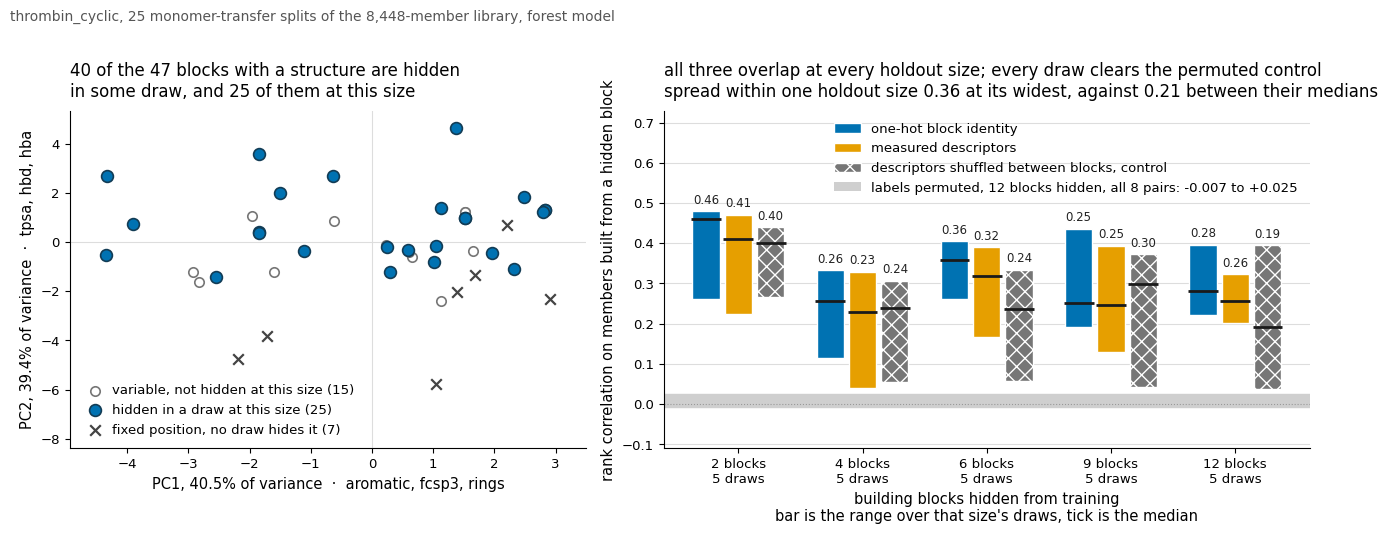


what the descriptors cannot say, from the record's own limitations:
  Descriptors are per-monomer. They describe the building blocks and capture nothing about the assembled macrocycle, its conformation or the ring.


In [12]:
# Two knobs. RUNG is the holdout size the left panel rings, and MODEL is the model the right
# panel draws. The table printed above the figure carries every holdout size and both models
# whichever pair is set, so neither knob can quietly drop a row.
RUNG, MODEL = 6, "forest"

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

MONO = ROOT / "data" / "raw" / "pepexplainer" / "thrombin_monomer_descriptors.csv"
GRID = RUNS / "monomers" / "thrombin_cyclic_grid.json"
CONTROL = RUNS / "monomers" / "thrombin_cyclic_held12_permuted.json"
LADDER = sorted((RUNS / "monomers").glob("thrombin_cyclic_held??.json"))

missing = [p for p in (MONO, GRID, CONTROL) if not p.exists()]
if missing:
    print("not on this machine: " + ", ".join(str(p.relative_to(ROOT)) for p in missing)
          + "\nrebuild with: python -m hpc_pilots monomers --landscape thrombin_cyclic --grid")
else:
    land = json.loads((ROOT / "hpc_pilots" / "configs" / "display.json").read_text())
    land = land["landscapes"]["thrombin_cyclic"]
    grid = json.loads(GRID.read_text())
    ctrl = json.loads(CONTROL.read_text())
    mono = pd.read_csv(MONO)

    print(f"{land['modality']}, endpoint {land['endpoint']}, {land['direction']}")
    print(f"  {ctrl['endpoint_warning'].split('.')[0]}.")

    # The absence row is derived from the missing structure rather than trusted from the flag,
    # because a flag and a blank SMILES disagreeing is exactly the kind of thing that would make
    # the projection below wrong without looking wrong.
    DESC = [c for c in mono.columns if c not in ("monomer", "group", "smiles", "is_absence")]
    absent = mono.smiles.isna()
    flag = mono.is_absence.astype(bool)
    drawn = mono[~absent].reset_index(drop=True)
    print(f"  {len(mono)} monomer rows, {len(drawn)} with a structure and {int(absent.sum())} "
          f"absence row ({', '.join(mono.monomer[absent])}), {len(DESC)} descriptors each, "
          f"{mono.group.nunique()} functional groups"
          + ("" if (absent == flag).all() else "   DISAGREE with the is_absence flag"))

    # A constant descriptor would divide the standardisation by zero and silently empty the
    # panel, so it is checked for and dropped by name rather than assumed away.
    flat = [d for d in DESC if drawn[d].std() == 0]
    if flat:
        print(f"  dropped from the projection, no spread over these blocks: {', '.join(flat)}")
    DESC = [d for d in DESC if d not in flat]

    # The projection is a plain PCA over the standardised descriptors, done here with an SVD so
    # the explained variance is the figure's own output and can be read off the axis labels.
    raw = drawn[DESC].to_numpy(float)
    # Population spread, not the sample estimate: these 47 blocks are the whole library and not
    # a sample from one, and the choice shows up in the distances printed below.
    z = (raw - raw.mean(0)) / raw.std(0)
    u, sv, vt = np.linalg.svd(z, full_matrices=False)
    share = sv ** 2 / (sv ** 2).sum()
    pc = u * sv
    radius = np.hypot(pc[:, 0], pc[:, 1])
    print(f"\nPCA over the {len(DESC)} standardised descriptors, {len(drawn)} blocks: "
          f"PC1 {share[0]:.1%} and PC2 {share[1]:.1%}, {share[:2].sum():.1%} together")
    axis_label = {}
    for i in (0, 1):
        load = pd.Series(vt[i], index=DESC).sort_values(key=abs, ascending=False)
        axis_label[i] = ", ".join(load.index[:3])
        print(f"  PC{i + 1} loads on " + ", ".join(f"{k} {v:+.2f}" for k, v in load.items()))

    # One row per draw per encoder-model cell. The grid is the record that carries replicates:
    # five independent draws of which blocks to hide at each of five holdout sizes.
    draws = pd.DataFrame([
        {"held_out": r["held_out_count"], "draw": i, "rho": v["held_out_spearman"],
         "blocks": tuple(sorted(r["held_out_monomers"])),
         "encoder": cell.split("/")[0], "model": cell.split("/")[1]}
        for i, r in enumerate(grid["rows"]) for cell, v in r["by_cell"].items()])
    rungs = sorted(draws.held_out.unique())
    per_rung = draws.groupby("held_out").draw.nunique()

    hidden = {n: set().union(*(set(b) for b in draws.blocks[draws.held_out == n]))
              for n in rungs}
    ever = set().union(*hidden.values())
    never = sorted(set(mono.monomer) - ever)
    print(f"\n{grid['draws']} draws over {len(rungs)} holdout sizes, {grid['replicates']} draws "
          f"each, unit of analysis: {grid['unit_of_analysis']}")
    print(f"  {len(ever)} of the {len(mono)} blocks are hidden in at least one draw, "
          f"{len(ever & set(drawn.monomer))} of those carrying a structure")
    group = dict(zip(mono.monomer, mono.group))
    print("  never hidden, and at positions the holdout does not touch: "
          + ", ".join(f"{m} ({group[m]})" for m in never))
    ring = np.array([m in hidden[RUNG] for m in drawn.monomer])
    print(f"  with {RUNG} blocks hidden, across its {per_rung.loc[RUNG]} draws: "
          f"{len(hidden[RUNG])} blocks of which {int(ring.sum())} carry a structure, "
          + ", ".join(f"{g} {c}" for g, c in
                      mono.group[mono.monomer.isin(hidden[RUNG])].value_counts().items()))
    print(f"  distance from the centre of the projection: those blocks median "
          f"{np.median(radius[ring]):.2f} against {np.median(radius):.2f} for all "
          f"{len(drawn)}, library maximum {radius.max():.2f}")

    # The same held-out set appears in both the grid and a locally re-run ladder record for some
    # draws, and the two were computed on different hosts, so the overlap is a reproduction
    # check and it is reported rather than assumed.
    by_set = {(r["held_out_count"], tuple(sorted(r["held_out_monomers"]))): r["by_cell"]
              for r in grid["rows"]}
    gap, shared, hosts, size = [], [], set(), set()
    for path in LADDER:
        rec = json.loads(path.read_text())
        cells = by_set.get((rec["held_out_count"], tuple(sorted(rec["held_out_monomers"]))))
        hosts.add(rec["provenance"]["host"].split(".")[0])
        size.add(rec["library_members"])
        if cells:
            shared.append(rec["held_out_count"])
            gap += [abs(r["held_out_spearman"] - cells[f"{r['encoder']}/{r['model']}"]
                        ["held_out_spearman"]) for r in rec["results"]]
    print(f"\ngrid run on {', '.join(grid['hosts'])}, the single-draw ladder records on "
          f"{', '.join(sorted(hosts))}. {len(shared)} of the {len(LADDER)} ladder records share "
          f"a held-out set with a grid draw\n  and agree with it to within {max(gap):.4f} "
          f"across all {len(gap)} of their encoder and model pairs, at "
          f"{', '.join(map(str, sorted(shared)))} blocks hidden")

    # Rungs as columns, so each row is one encoder and model read straight across. The two
    # columns after them are over all draws, which is where the single-draw ladder hides: the
    # worst and best draw of an arm are further apart than its rung medians are.
    tab = draws.pivot_table(index=["encoder", "model"], columns="held_out",
                            values="rho", aggfunc="median")
    tab.columns = [f"{n} hidden" for n in tab.columns]
    span = draws.groupby(["encoder", "model"]).rho.agg(["min", "max"])
    tab["worst draw"] = span["min"]
    tab["best draw"] = span["max"]
    print(f"\nheld-out rank correlation, median over the {grid['replicates']} draws at each "
          f"holdout size:\n")
    display(tab.round(3))

    ARMS = ("vocabulary", "descriptor", "descriptor_shuffled")
    wide = draws[draws.model == MODEL].pivot_table(index=["held_out", "draw"],
                                                   columns="encoder", values="rho")
    # Paired over the draw, because the two arms being compared were fitted on the same split.
    # A sign test is the weakest claim the 25 paired draws support and the only one that does
    # not assume a distribution over five draws per rung.
    print(f"\npaired over all {len(wide)} draws, {MODEL} model, sign test:")
    for a, b in (("descriptor", "descriptor_shuffled"), ("descriptor", "vocabulary")):
        d = wide[a] - wide[b]
        p = stats.binomtest(int((d > 0).sum()), len(d), 0.5).pvalue
        print(f"  {a} beats {b:<19} in {int((d > 0).sum()):2d} of {len(d)} draws, "
              f"median difference {d.median():+.3f}, p = {p:.4f}")
    for enc in ARMS:
        rho, p = stats.spearmanr(wide.index.get_level_values("held_out"), wide[enc])
        print(f"  {enc:<19} against how many blocks are hidden: rank correlation {rho:+.2f}, p = {p:.3f}")

    cv = [r["held_out_spearman"] for r in ctrl["results"]]
    print(f"\nlabel-permuted control, {ctrl['held_out_count']} blocks hidden, "
          f"{len(cv)} encoder and model pairs: {min(cv):+.3f} to {max(cv):+.3f}")

    # Okabe-Ito, and the shuffled control carries a hatch as well as a colour, so no statement
    # in either panel rests on the colour being seen.
    STYLE = {"vocabulary": ("#0072B2", ""), "descriptor": ("#E69F00", ""),
             "descriptor_shuffled": ("#767676", "xx")}
    LABEL = {"vocabulary": "one-hot block identity",
             "descriptor": "measured descriptors",
             "descriptor_shuffled": "descriptors shuffled between blocks, control"}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.4),
                                   gridspec_kw={"width_ratios": [1.0, 1.25]})

    # Three disjoint classes, so no block is drawn twice and the legend counts add to the 47.
    # The blocks no draw can hide are the fixed chemistry, the two cyclisation anchors, the
    # ender and the four linkers, and naming them keeps the open circles from reading as blocks
    # the experiment chose to spare.
    fixed = np.array([m in never for m in drawn.monomer])
    spare = ~ring & ~fixed
    ax1.scatter(pc[spare, 0], pc[spare, 1], s=46, facecolor="white", edgecolor="#767676",
                linewidth=1.2, zorder=3,
                label=f"variable, not hidden at this size ({int(spare.sum())})")
    ax1.scatter(pc[ring, 0], pc[ring, 1], s=72, facecolor="#0072B2", edgecolor="#123C55",
                linewidth=1.2, zorder=4,
                label=f"hidden in a draw at this size ({int(ring.sum())})")
    ax1.scatter(pc[fixed, 0], pc[fixed, 1], s=58, marker="x", color="#444444", linewidth=1.6,
                zorder=5, label=f"fixed position, no draw hides it ({int(fixed.sum())})")
    ax1.set_xlabel(f"PC1, {share[0]:.1%} of variance  ·  {axis_label[0]}", fontsize=10.5)
    ax1.set_ylabel(f"PC2, {share[1]:.1%} of variance  ·  {axis_label[1]}", fontsize=10.5)
    ax1.set_title(f"{len(ever & set(drawn.monomer))} of the {len(drawn)} blocks with a structure "
                  f"are hidden\nin some draw, and {int(ring.sum())} of them at this size",
                  fontsize=12, loc="left", pad=10)
    # Headroom under the cloud for the legend, which otherwise sits on top of the blocks in
    # the lower left corner of this projection.
    ax1.set_ylim(pc[:, 1].min() - 2.6, pc[:, 1].max() + 0.7)
    ax1.set_xlim(pc[:, 0].min() - 0.6, pc[:, 0].max() + 0.6)
    ax1.axhline(0, color="#DDDDDD", lw=0.8, zorder=1)
    ax1.axvline(0, color="#DDDDDD", lw=0.8, zorder=1)
    for side in ("top", "right"):
        ax1.spines[side].set_visible(False)
    ax1.legend(loc="lower left", frameon=False, fontsize=9.5, handletextpad=0.3)
    ax1.tick_params(labelsize=9.5)

    lo = {enc: np.array([wide[enc].loc[n].min() for n in rungs]) for enc in ARMS}
    hi = {enc: np.array([wide[enc].loc[n].max() for n in rungs]) for enc in ARMS}
    mid = {enc: np.array([wide[enc].loc[n].median() for n in rungs]) for enc in ARMS}
    x = np.arange(len(rungs))
    for k, enc in enumerate(ARMS):
        colour, hatch = STYLE[enc]
        at = x + (k - 1) * 0.26
        ax2.bar(at, hi[enc] - lo[enc], bottom=lo[enc], width=0.22, color=colour, hatch=hatch,
                edgecolor="white", linewidth=1.0, zorder=3)
        # The median is a tick inside the range rather than the top of a bar, because the five
        # draws are a spread over which blocks were hidden and not a magnitude.
        ax2.hlines(mid[enc], at - 0.12, at + 0.12, color="#1A1A1A", lw=2.0, zorder=5)
        for xi, yi, hv in zip(at, mid[enc], hi[enc]):
            ax2.text(xi, hv + 0.012, f"{yi:.2f}", ha="center", va="bottom", fontsize=8.5,
                     color="#222222", zorder=5)
    ax2.axhspan(min(cv), max(cv), color="#CFCFCF", zorder=2)
    ax2.axhline(0, color="#999999", lw=0.8, ls=":", zorder=2)
    # The control goes in the legend rather than beside its band, because at some settings of
    # MODEL the bars come down into the band and a floating label lands on top of one.
    key = [plt.Rectangle((0, 0), 1, 1, facecolor=STYLE[e][0], hatch=STYLE[e][1],
                         edgecolor="white") for e in ARMS]
    key.append(plt.Rectangle((0, 0), 1, 1, facecolor="#CFCFCF"))
    names = [LABEL[e] for e in ARMS] + [
        f"labels permuted, {ctrl['held_out_count']} blocks hidden, all {len(cv)} pairs: "
        f"{min(cv):+.3f} to {max(cv):+.3f}"]

    # The verdict in the panel is computed from the drawn intervals rather than typed, so
    # switching MODEL rewrites it instead of leaving a stale claim under a new picture.
    widest = max(hi[e][i] - lo[e][i] for e in ARMS for i in range(len(rungs)))
    shared_band = all(max(lo[e][i] for e in ARMS) <= min(hi[e][i] for e in ARMS)
                      for i in range(len(rungs)))
    above = min(lo[e].min() for e in ARMS) > max(cv)
    ax2.set_title(
        ("all three overlap at every holdout size" if shared_band else
         "at least one holdout size separates the three")
        + ("; every draw clears the permuted control" if above else
           "; some draws fall inside the permuted control")
        + f"\nspread within one holdout size {widest:.2f} at its widest, against "
          f"{max(m.max() - m.min() for m in mid.values()):.2f} between their medians",
        fontsize=12, loc="left", pad=10)
    ax2.set_xticks(x)
    ax2.set_xticklabels([f"{n} blocks\n{per_rung.loc[n]} draws" for n in rungs], fontsize=10.5)
    ax2.set_xlabel("building blocks hidden from training\n"
                   "bar is the range over that size's draws, tick is the median", fontsize=10.5)
    ax2.set_ylabel("rank correlation on members built from a hidden block", fontsize=10.5)
    ax2.set_xlim(-0.6, len(rungs) - 0.4)
    # Headroom above the tallest bar for the key, which is four rows deep and sits where the
    # bars never reach whichever surrogate MODEL names.
    ax2.set_ylim(min(-0.11, min(lo[e].min() for e in ARMS) - 0.03),
                 max(hi[e].max() for e in ARMS) + 0.07 + 0.045 * len(key))
    ax2.yaxis.grid(True, color="#DDDDDD", lw=0.8)
    ax2.set_axisbelow(True)
    for side in ("top", "right"):
        ax2.spines[side].set_visible(False)
    ax2.legend(key, names, loc="upper right", frameon=False, fontsize=9.5, ncol=1)
    ax2.tick_params(labelsize=9.5)
    fig.suptitle(f"thrombin_cyclic, {grid['draws']} monomer-transfer splits of the "
                 f"{max(size):,}-member library, {MODEL} model",
                 fontsize=10, x=0.004, ha="left", color="#555555")
    fig.tight_layout(rect=(0, 0, 1, 0.965))
    plt.show()

    print("\nwhat the descriptors cannot say, from the record's own limitations:")
    print("  " + next(l for l in ctrl["limitations"] if l.startswith("Descriptors")))

**The hidden blocks are ordinary members of the space, not an exotic corner of it.** Of the 47
blocks carrying a structure, 40 are hidden in at least one of the 25 draws. The seven never
hidden are the fixed chemistry: two cyclisation anchors, four linkers and the ender. Those sit at
positions the holdout does not touch. The hidden ones are spread through the cloud, a median 2.51
from the centre against 2.23 for all 47. So a weak transfer result here is not explained by the
experiment having hidden the strangest chemistry. That is the first thing worth checking, and the
reason the left panel is drawn at all.

**What holds is the separation from the permuted control.** That record hides twelve blocks from
the same library and shuffles the measurements. It keeps the shape of the experiment and destroys
the link between a member and its number. All eight of its lines land between -0.007 and +0.025.
The worst single draw in the panel is +0.039. So every draw sits clear of the control. A model
does carry real ranking information about members built from blocks it never saw measured.

**Nothing here separates by how many blocks are hidden.** The widest spread within one column is
0.36 and the widest gap between column medians is 0.21, both printed in the panel. So five draws
at one holdout size cover more ground than the sizes cover between them. Which blocks are hidden
matters at least as much as how many.

**Measured chemistry does not yet beat plain block identity.** Shuffling the descriptors between
blocks keeps the feature distribution and breaks the match to the real chemistry. The true
descriptors beat that control in 17 of 25 paired draws, which a sign test puts at p = 0.1078. The
line that wins has no chemistry in it at all.

**The reason is the last thing the cell prints, and it is the useful part.** These descriptors
are per block. They say nothing about the assembled ring, its conformation, or the cyclisation
that closes it. So a feature set scored on a building block in isolation is being asked to rank a
macrocycle. What would move this is a representation of the assembled member, not more holdout
sizes of the same ladder.

---
## 3 · One genome in, a ranked candidate list out

**This section runs the whole chain on SARS-CoV-2 and hands over the list at the end.** One
accession goes in, `NC_045512.2`, 29,903 nucleotides on a single segment.
`intake.rank_targets` is dispatched against NCBI and reviewed UniProt. The isolate itself is
deleted from the reference first, so identification has to work through whatever curated
relative is left. The main protease is then followed down, folded, measured and given a
library. What comes out is a table of candidates with the evidence behind each one.

**The chain is linear and there is a person in the middle of it.** Genome, ranked candidates,
someone chooses a target, measure its surface, define a library over it. Nothing here predicts
that any molecule binds anything. Nothing here is the intersection of two rankings.

**Two rankings over two different sets appear below, and they are kept apart on purpose.** The
live call ranks open reading frames. A six-frame caller sees one replicase polyprotein where a
chemist sees sixteen mature products, so the main protease is not a row in it. The per-target
ranks in the second table are mature chains, cut out of those reading frames by
`hpc_pilots.intake.decompose`. That function reads the chain boundaries off the matched
relative's UniProt entry and re-scores each chain from its own description. The cell prints
both lists, and the chain sitting at each place in the second, so the mapping is on screen.

**The last step runs after a target has been chosen and adds nothing to the ranking.** It asks
whether a model fitted on a first round could rank the library you would build. That is a
property of the library, not of the target. A library can be respecified and a target cannot,
so demoting a good candidate for a fixable reason would be the wrong move. The step keeps its
own block, with what was measured and what is assumed marked apart.

In [8]:
# ---------------------------------------------------------------------------------------
# The case. ACCESSION is the genome that goes in. HOLDOUT is the organism deleted from the
# reference before indexing, so identification has to work through a curated relative instead
# of recognising the isolate itself. TOP is how many of the longest ORFs get identified, and
# 30 is above the 28 this genome yields, so nothing is dropped for being short of the cut.
# CHOSEN is the candidate the gate at the end is applied to.
ACCESSION = "NC_045512.2"
HOLDOUT = "severe acute respiratory syndrome coronavirus 2"
TOP = 30
CHOSEN = "Mpro (nsp5)"          # as runs/amenability_gate.json now names it

# True dispatches the one call this section makes for real, which measured 13.5 to 14.2 s and
# 3 outbound requests over three runs on this machine. False replays its committed recording
# and touches nothing. §1.2 pins this tool to replay in MODE, and this knob overrides that
# pin, because dispatching it is what the section is for. Either way nothing tracebacks: a
# failed or unreachable call falls back to the recording and says so on screen.
RANK_LIVE = True

# How much protein surface one macrocycle residue covers when the ring lies flat on a patch.
# THIS IS AN ASSUMPTION THIS NOTEBOOK MAKES AND NOT A QUANTITY THIS PROJECT MEASURED. Nothing
# in `runs/` relates covered area to residue count. The round numbers are chosen so a reader
# can change them rather than trace them, and the band they sit in is printed below from two
# figures that are on the record: the area a macrocyclic peptide is reported to bury, quoted
# by the `why_not_a_druggability_score` field of `runs/surface_markers.json`, over the ring
# sizes `chemistry.library_spec` admits. The verdict is printed at every setting and never at
# one, because the whole step rests on this number.
AREA_PER_RESIDUE_SWEEP = (50.0, 75.0, 100.0)

# Positions the chemistry fixes in every member, and so cannot randomise: the chloroacetyl
# initiator that opens the ring and the cysteine that closes it through a thioether.
RING_FIXED = 2

# The batch geometry every gain in §2 is measured at, so the gate compares like with like.
FIRST_ROUND_CANDIDATES = 512
LABEL_BUDGET = 128

# The two records name the same five proteins differently, and neither spelling is derivable
# from the other, so the join is written out. A measured target this map does not reach is
# reported under the table rather than dropped.
#
# The polymerase used to be the one `None` here, carrying the comment "no surface was measured
# for it" -- which was true, and was the only place in this notebook that said so. It was never
# refused; the gate was a list of six written in a script and nobody had added it. The gate is
# generated from hpc_pilots/configs/structures.json now, so this row is a measurement.
SURFACE_OF = {"Spike glycoprotein": "Spike RBD",
              "Mpro / 3CLpro (nsp5)": "Mpro (nsp5)",
              "PLpro (nsp3)": "PLpro (nsp3)",
              "nsp13 helicase": "nsp13 helicase",
              "RdRp (nsp12)": "RdRp (nsp12)"}

# Where each staged dataset keeps its own description of itself. Each is written by
# `python -m hpc_pilots data` and excluded by .gitignore, like the §2 summary tables, so every
# read below has a branch for the files not being here.
STAGED = {"mpro": ROOT / "data/processed/targets/mpro",
          "spike_rbd_ace2": ROOT / "data/processed/method/spike_rbd_ace2",
          "four-site GB1": ROOT / "data/processed/binding"}

ADJUDICATION = ROOT / "ADJUDICATION_COMBINATORIAL_GAIN.md"
MARKERS = RUNS / "surface_markers.json"
NOT_MEASURED = "not measured"

# §1.2 defines the call renderer and the heading rule, and the cliff cell in §1.5 and the
# chemistry figure in §2.3 later bind their own
# tables to those two names, so by the time this cell runs the names no longer hold the
# functions. These two print the same two shapes. Everything that dispatches a tool, replays a
# recording or reads an experiment record is §1.2's and §1.3's and is used as it stands.
def heading(number, title, what_it_runs):
    print("\n" + "─" * 93)
    print(f"{number} · {title.upper()}")
    print(textwrap.fill(what_it_runs, 93))
    print("─" * 93)


def show_call(result):
    """One line of header, the arguments, the status and what the call spent."""
    m = result["measured"]
    if result["mode"] == "replay":
        tag = "replay of a committed recording, no network touched"
    elif m and m["network_calls"]:
        tag = f"LIVE, dispatched for real just now, {m['network_calls']} request(s) out"
    else:
        tag = "LIVE, dispatched for real just now, and no request left this machine"
    env = result["envelope"]
    head = result["tool"] + (f" v{env['tool_version']}" if env and env.get("tool_version")
                             else "")
    print(f"      {head}    [{tag}]")
    print(textwrap.fill(", ".join(f"{k}={_short(v)}"
                                  for k, v in result["arguments"].items()) or "none", 93,
                        initial_indent="        arguments  ",
                        subsequent_indent="                   "))
    for note in (result.get("fallback"), result.get("absent")):
        if note:
            print(textwrap.fill(note, 93, initial_indent="        note       ",
                                subsequent_indent="                   "))
    if result.get("live_attempt"):
        a = result["live_attempt"]
        print(f"        attempt    the live call spent {a['seconds']:.3f} s and tried "
              f"{a['network_calls']} request(s) before falling back")
    if result["refused"]:
        print(textwrap.fill(result["refused"]["message"], 93,
                            initial_indent=f"        refused    "
                                           f"{result['refused']['exception']}, ",
                            subsequent_indent="                   "))
    if env is not None:
        spent = ("the envelope records no cost, which is what a refusal before dispatch looks "
                 "like" if env["seconds"] is None else
                 f"{env['seconds']:.3f} s and {env['network_calls']} outbound request(s)"
                 + ("" if result["mode"] == "live" else ", as the recording measured them"))
        print(f"        status     {env['status']}, {spent}")
    print()


# Keep the imports this section needs on its own footing, so it does not depend on which of
# the cells above was re-run last. Both read local modules and reach no network.
from hpc_pilots import intake
from hpc_pilots.intake import MACROCYCLE_FOOTPRINT_A2 as FOOTPRINT


# ----------------------------------------------------------------- one accession in
heading("3.1", f"one accession in: {ACCESSION}",
        "intake.rank_targets, against NCBI and reviewed UniProt with the isolate deleted "
        "from the reference. Six-frame ORF calling, then identification through whatever "
        "curated relative is left, then the stated ranking rubric.")

live = call_tool("intake.rank_targets",
                 {"accession": ACCESSION, "exclude_organism": HOLDOUT, "top": TOP,
                  "record": False},
                 force="live" if RANK_LIVE else "replay",
                 recorded_as={"accession": ACCESSION})
show_call(live)

payload = live["envelope"]["value"] if live["envelope"] else None
if payload is None:
    print(textwrap.fill(
        "The ranked list itself is not in the recording, which keeps the arguments, the status "
        "and the cost and drops what came back, so it cannot be shown here. The candidate "
        "table below is read from the committed experiment records and does not depend on this "
        "call.", 93, initial_indent="      ", subsequent_indent="      "))
    print()
else:
    named = [t for t in payload["targets"] if t.get("score") is not None]
    blank = [t for t in payload["targets"] if t.get("score") is None]
    seg = "segment" if payload["segments"] == 1 else "segments"
    print(f"      {payload['genome_length_nt']:,} nt in {payload['segments']} {seg}, "
          f"identified against {payload['reference_entries']:,} reviewed "
          f"{payload['reference_scope']} protein entries, with\n      "
          f"{payload['reference_excluded_organism']} taken out of them first")
    print(f"      {payload['orfs_found']} ORFs called, {payload['orfs_ranked']} ranked, "
          f"{len(named)} identified through a relative, {len(blank)} unidentified\n")
    print(f"      {'place':<7}{'aa':>6}  {'score':>7}   identified as")
    for place, t in enumerate(named, 1):
        print(f"      {place:<7}{t['orf']['length_aa']:>6}  {t['score']:>7.3f}   "
              f"{t['name'][:53]}")
    if blank:
        sizes = [t["orf"]["length_aa"] for t in blank]
        print(f"\n      and {len(blank)} ORFs of {min(sizes)} to {max(sizes)} aa that no "
              "curated relative matched, carrying\n      no name and no score, which is what "
              "most of a six-frame call looks like")
    relatives = sorted({t["nearest_organism"] for t in named if t.get("nearest_organism")})
    print(textwrap.fill(f"recognised through {len(relatives)} curated relatives: "
                        + ", ".join(relatives), 93,
                        initial_indent="      ", subsequent_indent="      "))
    print()


# ----------------------------------------------------------------- one candidate followed down
heading("3.2", f"one candidate followed down: {CHOSEN}",
        "What the rest of §1 did to this one protein, in the order it did it. The fold and "
        "the surface are read from their committed records, because folding costs a call "
        "already made in §1.2 and the surface measurement costs 65 seconds. The library is "
        "defined live.")

gate_rec = record("amenability_gate")
chosen = next((t for t in gate_rec["targets"] if t["target"] == CHOSEN), None)
cited = json.loads(FOLDED_JSON.read_text()) if FOLDED_JSON.exists() else None

if cited:
    print(f"      folded        {cited['sequence_length']} residues, mean pLDDT "
          f"{cited['mean_plddt']:.2f}, {cited['model']}")
    print(f"                    {FOLDED_PDB.relative_to(ROOT)}, {cited['pdb_bytes']:,} bytes")
else:
    print(f"      folded        {FOLDED_PDB.relative_to(ROOT)} is not on this machine")

if chosen:
    low, high = chosen["patch_range"]
    print(f"      surface       largest unbroken exposed hydrophobic patch "
          f"{chosen['patch_median']:.0f} Å² median,")
    print(f"                    {low:.0f} to {high:.0f} across "
          f"{chosen['structures_measured']} structures of the same domain, spread "
          f"{chosen['patch_spread']:.0f}")
    print(textwrap.fill(f"{'yes' if chosen['exposed'] else 'no'}, annotated in "
                        + ", ".join(chosen["locations"]), 93,
                        initial_indent="      outside cell  ",
                        subsequent_indent="                    "))
else:
    print(f"      surface       runs/amenability_gate.json carries no row for {CHOSEN!r}; it "
          f"carries\n                    "
          f"{', '.join(t['target'] for t in gate_rec['targets'])}")

spec = call_tool("chemistry.library_spec", {})
sv = spec["envelope"]["value"] if spec["envelope"] else None
if sv:
    where = ("LIVE, local tables, no request left this machine" if spec["mode"] == "live"
             else "replay of a committed recording")
    print(textwrap.fill(
        f"{sv['initiator']} initiator, a randomised region of {sv['random_region'][0]} to "
        f"{sv['random_region'][1]} positions over {len(sv['elongator_alphabet'])} building "
        f"blocks, closed by {sv['closure_residue']} through a thioether, "
        f"{sv['theoretical_diversity']:,} sequences admitted  [{where}]", 93,
        initial_indent="      library       ", subsequent_indent="                    "))
else:
    print("      library       chemistry.library_spec returned nothing and has no recording "
          "to fall back to")
print()


# ----------------------------------------------------------------- the ranked candidates
heading("3.3", "the candidates, ranked, with what was measured for each",
        "Every SARS-CoV-2 candidate this project has a record for. The rank and the relative "
        "come from the intake experiment, the surface from the marker and gate experiments. A "
        "cell that reads 'not measured' is an absence and not a low score.")

ranks_csv = RUNS / "target_ranks.csv"
if not ranks_csv.exists():
    print(f"      {ranks_csv.relative_to(ROOT)} is not on this machine, so there is no "
          "ranked list to show.\n")
else:
    tr = pd.read_csv(ranks_csv)
    tr = tr[(tr.pathogen == "SARS-CoV-2") & (tr.holdout_level == "isolate")]
    surfaces = {t["target"]: t for t in gate_rec["targets"]}
    unjoined = [name for name in SURFACE_OF.values() if name and name not in surfaces]

    rows, outside, measured = [], [], 0
    for _, r in tr.sort_values("pipeline_rank").iterrows():
        s = surfaces.get(SURFACE_OF.get(r.target_protein) or "")
        # A row can now exist and carry no measurement, which is the point of generating the
        # gate from the config: "nothing could be measured here" is a row and not a silence.
        if s is not None and not s.get("measured", True):
            s = None
        # top_percent is dropped on purpose: it is the rank over the candidate count the
        # caption already prints, so the table would carry the same fact twice.
        row = {"rank": int(r.pipeline_rank), "candidate": r.target_protein,
               "recognised via": r.identified_via.split(";")[0].strip(),
               "outside the cell": NOT_MEASURED, "patch Å²": NOT_MEASURED,
               "range Å²": NOT_MEASURED, "gate": NOT_MEASURED,
               "drug status": r.drug_status}
        if s is not None:
            measured += 1
            low, high = s["patch_range"]
            verdict = intake.amenable({"hydrophobic_patch_area": s["patch_median"],
                                       "patch_area_min": low, "patch_area_max": high,
                                       "surface_exposed": s["exposed"]})
            row |= {"outside the cell": "yes" if s["exposed"] else "no",
                    "patch Å²": f"{s['patch_median']:.0f}",
                    "range Å²": f"{low:.0f} to {high:.0f}", "gate": verdict}
            if s["exposed"]:
                outside.append(r.target_protein)
        rows.append(row)

    board = pd.DataFrame(rows)
    print(f"      {len(board)} candidates, {measured} with a measured surface and "
          f"{len(board) - measured} without")
    print(textwrap.fill(
        f"rank is out of the {int(tr.candidate_proteins_ranked.iloc[0])} candidates the "
        f"pipeline identified and ranked, against {tr.reference_scope.iloc[0]} with "
        f"{HOLDOUT} removed.", 93, initial_indent="      ", subsequent_indent="      "))
    print(textwrap.fill(
        f"gate is hpc_pilots.intake.amenable, recomputed here. It asks whether the protein is "
        f"outside the cell at all before it looks at the area, then needs the whole measured "
        f"range at or above one macrocycle footprint of {FOOTPRINT:.0f} Å² for a yes and all "
        f"of it below {0.5 * FOOTPRINT:.0f} for a no, reporting anything in between as "
        f"borderline. patch Å² is the median and range Å² is the spread across replicate "
        f"structures of the same domain, so a wide range is a measurement that moves and not a "
        f"wide patch.", 93, initial_indent="      ", subsequent_indent="      "))
    print()
    display(board)

    # What the pipeline actually put in those five places, read out of the intake record
    # rather than inferred from the names in the table. This is the mapping between the two
    # rankings and it is the one thing a reader has to have to compare them at all.
    iv = record("intake_validation")
    case = next((c for c in iv["cases"] if c["accession"] == ACCESSION), None)
    if case:
        at = {row["rank"]: row["target"] for row in case["ranking"]}
        print(f"\n      what the pipeline ranked at each of those places, from "
              f"runs/intake_validation.json:")
        for place in board["rank"]:
            print(f"        {place:<4}{at.get(place, 'beyond the places the record lists')}")
        print(textwrap.fill(
            "These are mature chains cut out of the ORFs above by hpc_pilots.intake.decompose, "
            "which reads the chain boundaries off the matched relative's UniProt entry and "
            f"re-scores each chain from its own description. That is how {case['orfs_found']} "
            f"ORFs become {case['candidates_ranked']} candidates, and why a candidate's rank "
            "is the rank of a cleavage product and not of the ORF that carries it. The main "
            "protease, the papain-like protease and the helicase are all inside the replicase "
            "the ORF list ranks second, so the two rankings are over different things and "
            "their places are not comparable row for row.", 93,
            initial_indent="\n      ", subsequent_indent="      "))
        print(textwrap.fill(
            f"The spike row names a protein and not a chain, and the two records mean "
            f"different pieces of it: the pipeline put {at.get(1, 'its first candidate')} "
            f"first, while the surface was measured on the receptor-binding domain. Both are "
            f"the spike and neither is the other.", 93,
            initial_indent="\n      ", subsequent_indent="      "))
    if unjoined:
        print(f"\n      measured but not joined to a ranked candidate: "
              f"{', '.join(unjoined)}")
    agents = [f"{r.target_protein}: {r.drug_or_antibody}" for _, r in
              tr.sort_values("pipeline_rank").iterrows() if str(r.drug_or_antibody) != "none"]
    print(textwrap.fill("what is already approved or in the clinic against these, from the "
                        "same record: " + "; ".join(agents), 93,
                        initial_indent="\n      ", subsequent_indent="      "))
    print(textwrap.fill(
        f"outside the cell, so reachable without crossing a membrane: "
        f"{', '.join(outside) or 'none of the five'}. The other "
        f"{measured - len(outside)} measured are annotated inside the host cell, and patch "
        f"area does not make them reachable: the largest patch of the "
        f"{sum(1 for t in gate_rec['targets'] if t['measured'])} measured anywhere in that "
        f"record, "
        f"{max(t['patch_median'] for t in gate_rec['targets'] if t['measured']):.0f} Å², "
        f"sits on one of them.",
        93, initial_indent="      ", subsequent_indent="      "))
    print()


# ----------------------------------------------------------------- the gate on the library
heading("3.4", "after the target is chosen: a gate on the library",
        "Nothing above this line is a prediction about binding. This step asks one question "
        "about the library a campaign would build against the chosen target, before anything "
        "is synthesised: is it one a model fitted on a first round of measurements could "
        "rank from?")

# How thinly a first round covers the positions that vary is the quantity the adjudication
# names, and it is not a column in any table, so it is computed here from the staged batches
# themselves: how many candidates in one batch carry a value at a given varying position. A
# single-substitution scan spreads its batch over every position it touches. A library whose
# members all carry a value at every randomised position gives the whole batch to each one.
def coverage_of(key):
    """candidates per varying position, and the positions one batch touches, or None."""
    folder = STAGED.get(key)
    if folder is None or not (folder / "manifest.json").exists():
        return None
    man = json.loads((folder / "manifest.json").read_text())
    width = len(man.get("cardinalities") or man.get("positions") or [])
    if not (folder / "features.npy").exists() or not (folder / "splits.npz").exists():
        return None
    feat = np.load(folder / "features.npy")
    splits = np.load(folder / "splits.npz")
    batches = splits["evaluation"] if "evaluation" in splits else None
    size = int(batches.shape[1]) if batches is not None else FIRST_ROUND_CANDIDATES
    if width == 2:                       # (position, residue), one substitution a member
        if batches is None:
            return None
        touched = int(np.median([len(np.unique(feat[b, 0])) for b in batches]))
        return {"positions": touched, "per_position": size / touched, "batch": size}
    # Every member carries a building block at every position, so the whole batch speaks to
    # each one and the figure does not fall as the region gets longer.
    return {"positions": width, "per_position": float(size), "batch": size}


print("      MEASURED. The two SARS-CoV-2 datasets §2 staged, how thinly a first round of")
print(f"      {FIRST_ROUND_CANDIDATES} candidates covers the positions that vary in them, and "
      f"what a model fitted on\n      {LABEL_BUDGET} of those measurements won over choosing "
      f"at random.\n")

arm2 = []
target_csv = ARM2["target gain table"]
if target_csv.exists():
    tm = pd.read_csv(target_csv)
    cut = tm[(tm.landscape == "mpro") & (tm.labels == LABEL_BUDGET) & (tm.delay == 0)]
    wide = cut.pivot_table(index="pool", columns="policy", values="top_recall")
    if {"greedy", "random"} <= set(wide.columns):
        d = (wide["greedy"] - wide["random"]).dropna()
        arm2.append(("mpro", cut.target.iloc[0], d.mean(), int((d > 0).sum()), len(d)))
else:
    print(f"      {target_csv.relative_to(ROOT)} is not on this machine, so the main "
          "protease result cannot be\n      shown. Rebuild with "
          "`python -m hpc_pilots summarize`.")

method_csv = ARM2["method gain table"]
if method_csv.exists():
    mg = pd.read_csv(method_csv)
    hit = mg[(mg.landscape == "spike_rbd_ace2") & (mg.labels == LABEL_BUDGET)
             & (mg.policy == "greedy")]
    for _, r in hit.iterrows():
        arm2.append(("spike_rbd_ace2", r.protein, r.mean_paired_gain, int(r.pools_improved),
                     int(r.pools)))
else:
    print(f"      {method_csv.relative_to(ROOT)} is not on this machine, so the spike result "
          "cannot be shown.\n      Rebuild with `python -m hpc_pilots summarize`.")

if arm2:
    print(textwrap.fill(
        "varying is how many sequence positions differ anywhere in one batch and per pos is "
        "how many of that batch's candidates carry a building block at each of them, both "
        "counted here from the staged batches, and absent where the staged batches are not on "
        "this machine.", 93, initial_indent="      ", subsequent_indent="      "))
    print()
    print(f"      {'dataset':<17}{'protein':<31}{'varying':>8}{'per pos':>9}{'gain':>9}"
          f"{'batches':>10}")
    for key, protein, gain, better, total in arm2:
        cov = coverage_of(key)
        pos = f"{cov['positions']}" if cov else "absent"
        per = f"{cov['per_position']:.1f}" if cov else ""
        short = protein.replace("SARS-CoV-2 ", "")
        print(f"      {key:<17}{short[:30]:<31}{pos:>8}{per:>9}{gain:>+9.4f}"
              f"{f'{better} of {total}':>10}")
    print()
    print(textwrap.fill(
        "Both are single-substitution scans across a whole protein. Each member differs from "
        "the wild type at one position, so a batch spreads itself over every position the "
        "protein touches and only a handful of candidates speak to any one of them, and a "
        "model fitted on a first round of those measurements wins almost nothing. These two "
        "numbers are measurements of those two datasets and not verdicts on the targets.", 93,
        initial_indent="      ", subsequent_indent="      "))
    print()

# The calibration: one dataset narrowed to a given number of varying positions and otherwise
# unchanged, which is the one place the project varied coverage and held everything else
# fixed, plus the four-site library at the dense end. Parsed out of the adjudication's own
# check table rather than retyped, and the gate below prints nothing if the parse fails.
text = ADJUDICATION.read_text() if ADJUDICATION.exists() else ""
ladder = None
hit = re.search(r"`ha_h3` restricted to ([\d\s/]+) positions per pool \| greedy "
                r"([-+0-9.\s/]+);", text)
if hit:
    ladder = [(int(p), FIRST_ROUND_CANDIDATES / int(p), float(g),
               "one influenza H3 scan, narrowed to that many")
              for p, g in zip(hit.group(1).split("/"), hit.group(2).split("/"))]
    # The one staged dataset shaped like a display library: a randomised region over an
    # alphabet, every member carrying a value at all of it. Its position count comes from the
    # dataset's own description of itself and its batch size from the cell being quoted.
    four = re.search(r"GB1 four-site \(Wu 2016\) at (\d+)/\d+/[\d.]+%[^|]*\| greedy "
                     r"\+([0-9.]+) \((\d+)/(\d+)\)", text)
    cov4 = coverage_of("four-site GB1")
    if four and cov4:
        ladder.append((cov4["positions"], float(four.group(1)), float(four.group(2)),
                       f"a randomised library over {cov4['positions']} positions, "
                       f"{four.group(3)} of {four.group(4)}"))
    ladder.sort()

if ladder is None:
    why = ("is not on this machine" if not ADJUDICATION.exists()
           else "does not carry it in the form this cell reads")
    print(f"      The calibration comes from {ADJUDICATION.name}, which {why}, so the "
          f"step\n      below is not shown.\n")
else:
    print(textwrap.fill(
        f"The calibration, from {ADJUDICATION.name}, every cell at the same "
        f"{FIRST_ROUND_CANDIDATES} candidates and {LABEL_BUDGET} labels. Only the number of "
        "varying positions changes:", 93,
        initial_indent="      ", subsequent_indent="      "))
    print(f"\n      {'varying':>8}{'per pos':>9}{'gain':>9}   what was measured")
    for pos, per, gain, what in ladder:
        shown = "0.000" if gain == 0 else f"{gain:+.3f}"
        print(f"      {pos:>8}{per:>9.1f}{shown:>9}   {what}")
    print()
    print(textwrap.fill(
        "Fewer varying positions means more of the batch speaks to each one, and that is the "
        "direction the gain runs in. The two SARS-CoV-2 datasets above sit at the thin end of "
        "this, and the dense end of it is the shape of a display library: a randomised region "
        "over an alphabet, every member carrying a building block at every randomised "
        "position, so the whole batch speaks to each one.", 93,
        initial_indent="      ", subsequent_indent="      "))
    print()

print("      PROPOSED. The chain from a measured patch to a verdict on the library a campaign")
print("      would build, with the one step this project has not measured marked as assumed.\n")

# The band the assumed constant sits in, from the area a macrocycle is reported to bury over
# the ring sizes this library admits. Printed rather than asserted, and skipped if either
# source is absent.
band = None
if sv and MARKERS.exists():
    buried = re.search(r"buries (\d+)-(\d+) square angstroms",
                       json.loads(MARKERS.read_text()).get("why_not_a_druggability_score", ""))
    if buried:
        ring_lo = sv["random_region"][0] + RING_FIXED
        ring_hi = sv["random_region"][1] + RING_FIXED
        band = (int(buried.group(1)) / ring_hi, int(buried.group(2)) / ring_lo,
                int(buried.group(1)), int(buried.group(2)), ring_lo, ring_hi)

if chosen is None or sv is None or ladder is None:
    print("      Not shown. This step needs three things and at least one is absent on this "
          "machine:")
    print(f"        a measured patch for {CHOSEN!r}: {'present' if chosen else 'absent'}")
    print(f"        a library definition from chemistry.library_spec: "
          f"{'present' if sv else 'absent'}")
    print(f"        the calibration in {ADJUDICATION.name}: "
          f"{'present' if ladder else 'absent'}\n")
else:
    patch = chosen["patch_median"]
    lo_pos, hi_pos = sv["random_region"]
    mid_area = AREA_PER_RESIDUE_SWEEP[len(AREA_PER_RESIDUE_SWEEP) // 2]
    print(textwrap.fill(
        f"{CHOSEN} is the worked case, because it is the protein §1 folded and measured. The "
        f"table above refuses it on where it sits in the cell, so a campaign choosing from "
        f"that table would take the spike. The steps are the same whichever row is chosen.",
        93, initial_indent="      ", subsequent_indent="      "))
    print()
    print(f"        measured     {patch:.0f} Å² patch on {CHOSEN}, median over "
          f"{chosen['structures_measured']} structures")
    assumed = ("the ring covers that patch, and each residue covers a fixed share of it. "
               "Swept below, and not measured here.")
    if band:
        assumed = (f"the ring covers that patch, and each residue covers a fixed share of it. "
                   f"Swept below over {band[0]:.0f} to {band[1]:.0f} Å² a residue, which is "
                   f"the {band[2]} to {band[3]} Å² a macrocycle is reported to bury in "
                   f"runs/surface_markers.json over the {band[4]} to {band[5]} ring residues "
                   f"this library admits. Not measured here.")
    print(textwrap.fill(assumed, 93, initial_indent="        ASSUMED      ",
                        subsequent_indent="                     "))
    print(f"        follows      a ring, less the {RING_FIXED} positions the chemistry fixes, "
          f"so a randomised region")
    print(f"        checked      against the {lo_pos} to {hi_pos} positions "
          f"chemistry.library_spec admits\n")

    print(f"      {'Å² per residue':<16}{'ring':>6}{'random':>8}   "
          f"can this library format build that region?")
    for area in AREA_PER_RESIDUE_SWEEP:
        ring = patch / area
        length = max(1, round(ring) - RING_FIXED)
        buildable = ("yes" if lo_pos <= length <= hi_pos else
                     f"no, {'longer' if length > hi_pos else 'shorter'} than the "
                     f"{lo_pos} to {hi_pos} it admits")
        print(f"      {area:<16.0f}{ring:>6.1f}{length:>8}   {buildable}")
    print()
    asks = [(t["target"].replace("SARS-CoV-2 ", ""),
             max(1, round(t["patch_median"] / mid_area) - RING_FIXED))
            for t in gate_rec["targets"] if t["target"].startswith("SARS-CoV-2")]
    outside_format = [name for name, n in asks if not lo_pos <= n <= hi_pos]
    print(textwrap.fill(
        f"This is the step that separates one target from another, and on the measured rows it "
        f"does. At {mid_area:.0f} Å² a residue the same arithmetic asks for "
        + ", ".join(f"{n} positions against {name}" for name, n in asks)
        + f". {len(outside_format)} of those {len(asks)} want a randomised region outside the "
        f"{lo_pos} to {hi_pos} this format admits, which is a design decision a campaign can "
        f"take before it orders anything rather than a reason to drop a target.", 93,
        initial_indent="      ", subsequent_indent="      "))
    print()
    print(textwrap.fill(
        f"Whether a model fitted on a first round could rank that library does not turn on "
        f"its length. Every member carries a building block at every randomised position, so "
        f"a batch of {FIRST_ROUND_CANDIDATES} gives {FIRST_ROUND_CANDIDATES} candidates to "
        f"each varying position whether the region is {lo_pos} positions or {hi_pos}, which is "
        f"the dense end of the calibration above and the regime of the largest gain measured "
        f"anywhere in this project. That is the verdict, and the honest form of it is that it "
        f"follows from the shape of a display library rather than from anything measured about "
        f"this target, on datasets none of which holds a macrocycle, a building block outside "
        f"the twenty canonical residues, or a ring closure.", 93,
        initial_indent="      ", subsequent_indent="      "))

    enough = re.search(r"`mpro` at Spearman ([\d.]+) with greedy (\S+?);", text)
    if enough:
        print(textwrap.fill(
            f"Two things travel with it. Dense coverage is necessary and not sufficient, which "
            f"{ADJUDICATION.name} states against this very protein: a model that reaches a "
            f"rank correlation of {float(enough.group(1)):.2f} against truth there still came "
            f"out {float(enough.group(2).replace(chr(8722), '-')):+.2f} against choosing at "
            f"random, because the ranking does not resolve the top of the list. So a library "
            f"that clears the condition is worth fitting on and not certain to pay.", 93,
            initial_indent="\n      ", subsequent_indent="      "))
    decay = re.search(r"normalised gain ([\d.\s/]+) at ([\d,\s/]+);", text)
    if decay:
        sizes = [s.strip() for s in decay.group(2).split("/")]
        gains = [float(g) for g in decay.group(1).split("/")]
        print(textwrap.fill(
            f"And it holds for focused batches only. On that same four-site library at a fixed "
            f"{LABEL_BUDGET}-label budget the gain falls from {gains[0]:.3f} at {sizes[0]} "
            f"candidates to {gains[-1]:.3f} at {sizes[-1]}, so this speaks to deconvolution and "
            f"focused maturation over hundreds to a few thousand members and says nothing about "
            f"one selection round over the {sv['theoretical_diversity']:,} sequences the "
            f"library admits.", 93,
            initial_indent="\n      ", subsequent_indent="      "))
    print(textwrap.fill(
        "What would replace the assumed step with a measurement is buried area per residue "
        "read off deposited macrocycle complexes, which is a small piece of work and not a new "
        "method.", 93, initial_indent="\n      ", subsequent_indent="      "))
    print()


─────────────────────────────────────────────────────────────────────────────────────────────
3.1 · ONE ACCESSION IN: NC_045512.2
intake.rank_targets, against NCBI and reviewed UniProt with the isolate deleted from the
reference. Six-frame ORF calling, then identification through whatever curated relative is
left, then the stated ranking rubric.
─────────────────────────────────────────────────────────────────────────────────────────────


      intake.rank_targets v2    [LIVE, dispatched for real just now, 3 request(s) out]
        arguments  accession='NC_045512.2', exclude_organism='severe acute respiratory
                   syndrome coronavirus 2', top=30, record=False
        status     ok, 15.275 s and 3 outbound request(s)

      29,903 nt in 1 segment, identified against 17,512 reviewed viral protein entries, with
      severe acute respiratory syndrome coronavirus 2 taken out of them first
      28 ORFs called, 28 ranked, 12 identified through a relative, 16 unidentified

      place      aa    score   identified as
      1        1282    6.986   SPIKE_BCHK3 Spike glycoprotein
      2        2595    6.904   R1AB_SARS Replicase polyprotein 1ab
      3        4405    5.737   R1A_BCHK3 Replicase polyprotein 1a
      4         222    5.520   VME1_BC279 Membrane protein
      5         275    4.556   AP3A_BC279 Protein 3
      6         419    3.501   NCAP_BCRP3 Nucleoprotein
      7          75    2.585   VEMP_SARS

,rank,candidate,recognised via,outside the cell,patch Å²,range Å²,gate,drug status
0,1,Spike glycoprotein,Bat coronavirus HKU3,yes,842,592 to 1088,borderline,approved (EUA)
1,2,Mpro / 3CLpro (nsp5),Bat coronavirus HKU3,no,651,625 to 825,no,approved
2,5,RdRp (nsp12),Bat coronavirus HKU3,no,487,363 to 1683,no,approved
3,6,PLpro (nsp3),Bat coronavirus HKU3,no,405,358 to 410,no,research target
4,7,nsp13 helicase,Bat coronavirus HKU3,no,1247,998 to 1303,no,research target



      what the pipeline ranked at each of those places, from runs/intake_validation.json:
        1   Spike protein S2'
        2   3C-like proteinase nsp5
        5   RNA-directed RNA polymerase nsp12
        6   Papain-like protease nsp3
        7   Helicase nsp13

      These are mature chains cut out of the ORFs above by hpc_pilots.intake.decompose,
      which reads the chain boundaries off the matched relative's UniProt entry and re-scores
      each chain from its own description. That is how 28 ORFs become 23 candidates, and why
      a candidate's rank is the rank of a cleavage product and not of the ORF that carries
      it. The main protease, the papain-like protease and the helicase are all inside the
      replicase the ORF list ranks second, so the two rankings are over different things and
      their places are not comparable row for row.

      The spike row names a protein and not a chain, and the two records mean different
      pieces of it: the pipeline put Spike

**The table is a shortlist and not a score, and where the protein sits in the cell is what
makes it one.** Four of the five candidates have a measured surface and one does not. That row
says so in words rather than leaving a blank, because an empty cell would read as a low score.
Of the four, only the spike is annotated outside the cell. A macrocycle has to reach its target
without crossing a membrane, so the spike is the only one of the five currently reachable.

**A large patch never promotes a row here.** The helicase carries the largest patch of the six
proteins measured anywhere in that record. It also sits inside the host cell, on the
replication machinery. That is why the gate reads localisation before it reads area. The main
protease already has an approved inhibitor, which says the site is bindable. It also says a new
molecule would be competing with a marketed drug.

**So read the table top down and stop at the first reachable row.** For SARS-CoV-2 that is the
spike at rank 1. The gate calls it borderline, because its measured patch straddles one
macrocycle footprint across the five structures it was measured on. That is worth repeating on
more structures before a campaign commits to it. The place itself belongs to a spike cleavage
product, while the surface was measured on the receptor-binding domain. The cell prints both
under the table. So that row is the spike at two granularities, not one measurement of one
chain. Change `ACCESSION` and `HOLDOUT` at the top of the cell and the same two tables come
back for another pathogen.

**After a target is chosen, one more question is worth asking before anything is ordered.**
§3.4 keeps what was measured and what is assumed in separate blocks. The measured part is the
two SARS-CoV-2 datasets §2 staged. Both are single-substitution scans over a whole protein. A
first round of candidates therefore spreads itself over two hundred positions and more, and a
model fitted on it wins almost nothing. The calibration printed beside them is the one place
this project varied that coverage with everything else held fixed. The gain runs with how much
of a batch speaks to each varying position. A display library sits at the dense end, because
every member carries a building block at every randomised position.

**The proposed part is one link the repository does not contain, and it is marked as such.**
Going from a measured patch to a randomised-region length needs a figure for how much surface
one macrocycle residue covers. Nothing in `runs/` measures it. So it sits in an uppercase
constant, is swept over three settings rather than shown at one, and prints the band it sits in
from the record. What that step buys is concrete. The implied region can be compared against
the 4 to 8 positions `chemistry.library_spec` admits. On the four measured surfaces the answer
differs from target to target. That is a design decision a campaign can take, not a reason to
drop a candidate. Measuring buried area per residue off deposited macrocycle complexes would
replace the assumption with a number, and that is a small piece of work.

**Two limits travel with the verdict and both are printed beside it.** Dense coverage is
necessary and not sufficient, which the adjudication record states against the main protease
itself. And the measured gain decays steeply with batch size at a fixed label budget. So §3.4
speaks to deconvolution and focused maturation, over hundreds to a few thousand members, rather
than to one selection round over the whole library. Nothing behind any of it holds a
macrocycle, a building block outside the twenty canonical residues, or a ring closure. That is
the gap a SynX campaign is the natural way to close.